<a href="https://colab.research.google.com/github/imguru-mooc/AI_CAMPUS/blob/main/QP-day4/QP_Day4_lecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a> <a href="https://kaggle.com/kernels/welcome?src=https://github.com/imguru-mooc/AI_CAMPUS/blob/main/QP-day4/QP_Day4_lecture.ipynb" target="_blank"><img src="https://kaggle.com/static/images/open-in-kaggle.svg" alt="Open In Kaggle"/></a>

# Quantization·Pruning Day 4 — QAT: Quantization-Aware Training

**온디바이스 AI · Quantization·Pruning 4/6 · 11/19(목)** · Google Colab 또는 Kaggle · **GPU (T4) 권장** · PyTorch · NVIDIA ModelOpt · TensorRT 10

어제까지는 **학습이 끝난 모델**의 숫자 그릇만 바꿨습니다 (PTQ). 8비트에서는 ResNet-20 이 거의 손실 없이 INT8 이 됐지만, 비트를 더 줄이면 이야기가 달라집니다. 오늘은

1. weight 를 **3 ~ 4비트**로 줄여 PTQ 가 무너지는 것을 보고,
2. 학습 중에 양자화를 미리 겪게 하는 **fake quantization** 과 **STE** 를 직접 만들어 **QAT** 로 정확도를 되찾고,
3. 같은 일을 NVIDIA **ModelOpt** 로 해서 **QDQ ONNX → TensorRT INT8** 까지 배포합니다.
4. 마지막으로 **PTQ vs QAT 5종 대결**로 "QAT 가 필요한 경우" 를 숫자로 결론 냅니다.

> **PTQ 의 한계 (저비트)** → **fake quant** → **STE** → **직접 만드는 QAT** → **ModelOpt PTQ · QAT** → **QDQ ONNX · TensorRT** → **PTQ vs QAT 대결**

오늘의 목표

1. 비트 수에 따른 PTQ 정확도를 재고, QAT 가 필요한 상황(저비트 · 작은 모델 · depthwise)을 설명할 수 있다.
2. Day 1 의 양자화 식으로 **fake quantization** (quantize → dequantize) 함수 · 모듈을 만들 수 있다.
3. round 의 기울기가 0 인 문제와 **STE** 를 `torch.autograd.Function` 으로 구현하고, 범위 밖 기울기 차단을 확인할 수 있다.
4. BN 을 먼저 접고 Conv/Linear 에 FakeQuant 를 넣어 **직접 QAT** 하고 PTQ 와 비교할 수 있다.
5. `mtq.quantize` 로 PTQ, 이어서 fine-tuning 으로 QAT 하고, 체크포인트를 저장 · 복원할 수 있다.
6. QAT 모델을 **QDQ ONNX** 로 내보내 보정 없이 TensorRT INT8 엔진을 만들 수 있다.

| 교시 | 시간 | 주제 |
|---|---|---|
| 1 | 09:00–09:50 | PTQ 의 한계 — 비트를 줄이면 |
| 2 | 10:00–10:50 | Fake Quantization — 학습 그래프 안의 양자화 |
| 3 | 11:00–11:50 | STE — round 의 기울기 문제 |
| 4 | 13:00–13:50 | 직접 만드는 QAT — BN folding · FakeQuant · 3 epoch |
| 5 | 14:00–14:50 | NVIDIA ModelOpt PTQ |
| 6 | 15:00–15:50 | ModelOpt QAT — 정확도 곡선 · 체크포인트 |
| 7 | 16:00–16:50 | QAT 모델 배포 — QDQ ONNX · TensorRT INT8 |
| 8 | 17:00–17:50 | 미니 프로젝트 — PTQ vs QAT 대결 · 채점 |

**노트북 사용법**

1. 아래 **0. 실행 환경 준비**대로 내 사본을 만들고 **GPU (T4)** 런타임으로 바꿉니다. 오늘은 **학습**이 있습니다 — GPU 에서는 QAT 3 epoch 가 수십 초, CPU 에서는 약 1.5분씩 걸립니다 (CPU 로도 끝까지 됩니다).
2. **✍️ 직접 구현** 셀은 **교시마다 2문제**입니다. `# TODO` 를 직접 작성합니다. 확인 셀이 `✅` 를 출력하면 정답입니다. 막히면 **💡 힌트** 셀 (실행할 때마다 하나씩 더).
3. **🔒 정답 보기** 셀은 **실습마다 다른 잠금 코드**로 잠겨 있습니다. 정답을 연 기록은 8교시 채점 셀에 표시됩니다.
4. **▶ 예제 (제공 코드)** 셀은 직접 구현이 아닙니다 — 그대로 실행하고 출력 · 해설을 읽습니다. 뒤 교시가 이 셀의 함수 · 변수를 쓰므로 **건너뛰지 말고 실행**하세요.
5. **학습 결과 · 시간은 GPU · 세션마다 조금씩 다릅니다.** 교안의 숫자는 강사 실측 **예시**입니다.
6. 8교시 미니 프로젝트는 끝에 있습니다 (정답 셀 없음). 채점 셀 결과가 보이는 상태로 제출합니다.
7. 수업이 끝나면 **Day 4 복습 퀴즈**(HTML)를 풀고 제출합니다.

## 0. 실행 환경 준비 — Colab 또는 Kaggle

| 단계 | Google Colab | Kaggle |
|---|---|---|
| 열기 | 맨 위 **Open in Colab** 배지 | 맨 위 **Open in Kaggle** 배지 (또는 *File → Import Notebook* 에서 GitHub 주소 붙여넣기) |
| 내 사본 | *파일 → Drive에 사본 저장* | 열면 내 계정의 노트북으로 만들어짐 · 작업 후 **Save Version** |
| **GPU** | *런타임 → 런타임 유형 변경 → T4 GPU* | 오른쪽 패널 *Session options → Accelerator → **GPU T4 x2*** |
| 인터넷 | 기본으로 켜져 있음 | *Session options → **Internet On*** (처음 한 번 **전화번호 인증**) — ModelOpt · TensorRT 설치에 필요 |
| 생성형 AI | 이 노트북은 **생성형 AI 기능이 숨겨진 상태**로 배포됩니다. **다시 켜지 마세요** — 제출 파일에서 이 설정을 확인합니다. *도구 → 설정 → AI 지원* 의 **AI 기반 인라인 완성 표시** 도 꺼 두세요 | 노트북 안에 AI 자동 완성 없음 |
| 숨김 셀 | 🔒 · 🖼 · 💡 셀은 코드가 접혀 있음 | 코드가 보이지만 그대로 실행하면 됨 |

> 아래 **환경 셀**을 실행하면 `실행 환경`, GPU, `ModelOpt` · `tensorrt` 버전이 출력됩니다. 처음에는 설치에 2~3분 걸립니다.

### 📚 오늘의 온라인 자료

| 자료 | 링크 |
|---|---|
| 🎬 애니메이션 (시뮬레이션 8개) | [https://imguru-mooc.github.io/AI_CAMPUS/QP-day4/animation.html](https://imguru-mooc.github.io/AI_CAMPUS/QP-day4/animation.html) |
| 📝 Day 4 복습 퀴즈 (수업이 끝난 뒤, 24문항) | [https://imguru-mooc.github.io/AI_CAMPUS/QP-day4/review_quiz.html](https://imguru-mooc.github.io/AI_CAMPUS/QP-day4/review_quiz.html) |
| 🖥 슬라이드 (PDF) | [https://imguru-mooc.github.io/AI_CAMPUS/QP-day4/QP_Day4.pdf](https://imguru-mooc.github.io/AI_CAMPUS/QP-day4/QP_Day4.pdf) |

**오늘의 데이터 · 모델** — Day 2 · 3 의 **ResNet-20** (`resnet20_cifar10.pt`, FP32 0.846), CIFAR-10 **학습용 10,000장** (`cifar_train10k.npz`, QAT fine-tuning 용), 보정용 500장 · 평가용 2,000장 (Day 2 와 같음 — 학습용과 겹치지 않음). 모두 노트북이 자동으로 내려받습니다.

> FP32 모델은 미리 학습해 둔 것을 씁니다. 처음부터 학습하는 것은 VB Day 2 에서 했으므로 오늘은 **이미 학습된 모델을 짧게 fine-tuning** 하는 QAT 만 합니다.

In [ ]:
# ▶ 환경 셀 — 런타임이 끊기면 이 셀부터 다시 실행하세요
import os, sys, re, glob, json, copy, time, shutil, urllib.request, warnings, inspect, contextlib, io, importlib.util, subprocess
from collections import Counter

# ── 실행 환경 감지 (Colab · Kaggle · 내 PC) ──
try:
    import google.colab  # noqa: F401
    PLATFORM = "Colab"
except ImportError:
    PLATFORM = "Kaggle" if ("KAGGLE_KERNEL_RUN_TYPE" in os.environ or os.path.isdir("/kaggle/working")) else "Local"
if PLATFORM == "Kaggle":
    os.chdir("/kaggle/working")

def _online(url="https://raw.githubusercontent.com", timeout=5):
    try:
        urllib.request.urlopen(url, timeout=timeout); return True
    except Exception:
        return False
ONLINE = _online()

import torch, torch.nn as nn, torch.nn.functional as F
GPU_OK = torch.cuda.is_available()

# ── 설치 (없을 때만): onnx · onnxruntime, GPU 이면 TensorRT 10 ──
_need = [p for p in ["onnx", "onnxruntime"] if importlib.util.find_spec(p) is None]
if importlib.util.find_spec("modelopt") is None:
    _need.append("nvidia-modelopt==0.48.0")
if GPU_OK and importlib.util.find_spec("tensorrt") is None:
    _need.append("tensorrt-cu12==10.16.1.11")
if _need:
    print("설치:", _need, "— 처음 한 번 2~3분")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_need], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import onnx, onnxruntime as ort
from onnx import numpy_helper
from onnxruntime.quantization import quantize_static, CalibrationDataReader, QuantFormat, QuantType, CalibrationMethod
from onnxruntime.quantization.shape_inference import quant_pre_process
from IPython.display import display
import modelopt.torch.quantization as mtq
import modelopt.torch.opt as mto
try:
    import tensorrt as trt
    TRT_OK = GPU_OK
except ImportError:
    trt, TRT_OK = None, False

warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)
DEV = "cuda" if GPU_OK else "cpu"
pd.set_option("display.width", 160)
torch.manual_seed(0); np.random.seed(0)
BASE = "https://imguru-mooc.github.io/AI_CAMPUS/QP-day4"
RAW = "https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day4"
EXPORT_KW = {"dynamo": False} if "dynamo" in inspect.signature(torch.onnx.export).parameters else {}
CPU = ["CPUExecutionProvider"]
BACKEND = "TensorRT" if TRT_OK else "ORT CPU"

print(f"실행 환경: {PLATFORM} | 작업 폴더: {os.getcwd()} | 인터넷: {'연결됨' if ONLINE else '끊김'} | GPU: {torch.cuda.get_device_name(0) if GPU_OK else '없음'}")
import modelopt
print(f"PyTorch {torch.__version__} | onnx {onnx.__version__} | onnxruntime {ort.__version__} | ModelOpt {modelopt.__version__} | TensorRT {trt.__version__ if trt else '없음'}")
if not TRT_OK:
    print("⚠️ GPU / TensorRT 없음 — 학습은 CPU 로 (3 epoch 에 약 1.5분씩), 7 · 8교시 엔진 셀은 ONNX Runtime CPU 로 대신 잽니다.")

def fetch(name):
    """data/<name> 이 없으면 강의 자료 서버(GitHub Pages → GitHub 원본 순)에서 내려받는다"""
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        for url in [f"{BASE}/data/{name}", f"{RAW}/data/{name}"]:
            try:
                urllib.request.urlretrieve(url, path)
                break
            except Exception as e:
                if os.path.exists(path): os.remove(path)
                print("내려받기 실패:", url, "→", e)
        else:
            raise FileNotFoundError(f"{name} 을 내려받지 못했습니다. 인터넷 연결을 확인하거나 강사에게 받은 파일을 data 폴더에 올리세요.")
    return path

@contextlib.contextmanager
def quiet():
    """양자화 도구의 긴 로그를 숨긴다"""
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        yield

def size_kb(path):
    return os.path.getsize(path) / 1024

def make_session(path, threads=1):
    so = ort.SessionOptions(); so.intra_op_num_threads = threads
    return ort.InferenceSession(path, so, providers=CPU)

def bench_fn(fn, n=100, warm=10):
    """OT Day 3 · Day 2 의 bench — fn() 을 warm 번 실행한 뒤 n 번 재서 ms 통계"""
    for _ in range(warm):
        fn()
    t = []
    for _ in range(n):
        t0 = time.perf_counter(); fn(); t.append((time.perf_counter() - t0) * 1000)
    t = np.array(t)
    return {"mean": float(t.mean()), "p95": float(np.percentile(t, 95)), "fps": float(1000 / t.mean())}

# ── TensorRT (GPU 일 때만) — OT Day 5 의 TRTInfer 그대로 ──
if TRT_OK:
    LOGGER = trt.Logger(trt.Logger.WARNING)
    RUNTIME = trt.Runtime(LOGGER)

    class TRTInfer:
        def __init__(self, engine_path):
            self.engine = RUNTIME.deserialize_cuda_engine(open(engine_path, "rb").read())
            self.context = self.engine.create_execution_context()
            names = [self.engine.get_tensor_name(i) for i in range(self.engine.num_io_tensors)]
            self.inputs = [n for n in names if self.engine.get_tensor_mode(n) == trt.TensorIOMode.INPUT]
            self.outputs = [n for n in names if self.engine.get_tensor_mode(n) == trt.TensorIOMode.OUTPUT]
            self.buf = {n: torch.empty(tuple(self.engine.get_tensor_shape(n)), dtype=torch.float32, device="cuda") for n in names}
            for n in names:
                self.context.set_tensor_address(n, self.buf[n].data_ptr())
            self.input_shape = tuple(self.engine.get_tensor_shape(self.inputs[0]))

        def __call__(self, x):
            self.buf[self.inputs[0]].copy_(torch.from_numpy(np.ascontiguousarray(x, dtype=np.float32)))
            self.context.execute_async_v3(torch.cuda.current_stream().cuda_stream)
            torch.cuda.synchronize()
            return self.buf[self.outputs[0]].cpu().numpy()

        def __repr__(self):
            return f"TRTInfer(in={self.inputs} {self.input_shape}, out={self.outputs})"

    def build_engine(onnx_path, engine_path, fp16=False, int8=False):      # Day 3 실습 4-2
        builder = trt.Builder(LOGGER)
        network = builder.create_network(0)
        parser = trt.OnnxParser(network, LOGGER)
        if not parser.parse_from_file(onnx_path):
            raise RuntimeError("\n".join(str(parser.get_error(i)) for i in range(parser.num_errors)))
        config = builder.create_builder_config()
        config.set_memory_pool_limit(trt.MemoryPoolType.WORKSPACE, 1 << 30)
        if fp16:
            config.set_flag(trt.BuilderFlag.FP16)
        if int8:
            config.set_flag(trt.BuilderFlag.INT8)
        blob = builder.build_serialized_network(network, config)
        if blob is None:
            raise RuntimeError("빌드 실패 — 위 로그를 확인하세요")
        with open(engine_path, "wb") as f:
            f.write(blob)
        return engine_path

def build_once(onnx_path, engine_path, fp16=False, int8=False):
    """엔진이 이미 있으면 다시 만들지 않는다 (Day 3)"""
    if not os.path.exists(engine_path):
        t0 = time.time(); build_engine(onnx_path, engine_path, fp16=fp16, int8=int8)
        print(f"빌드 {engine_path} — {time.time() - t0:.0f} 초")
    return engine_path

import hashlib, base64, datetime
_HINT_N = {}
def show_hint(no, blob):
    # 💡 실행할 때마다 힌트를 하나씩 더 보여 준다
    hints = base64.b64decode(blob).decode("utf-8").split("\x1e")
    k = min(_HINT_N.get(no, 0) + 1, len(hints)); _HINT_N[no] = k
    for i in range(k):
        print(f"💡 힌트 {i + 1}/{len(hints)} — {hints[i]}")
    print("(다시 실행하면 다음 힌트)" if k < len(hints) else "(힌트를 모두 봤습니다 — 이제 직접 구현해 보세요)")

def show_answer(no, blob):
    # 🔒 잠금된 정답 보기 — 강사가 알려 준 '실습별' 잠금 코드가 있어야 열린다
    raw = base64.b64decode(blob); tag, body = raw[:8], raw[8:]
    for _ in range(2):
        code = input(f"🔒 실습 {no} 잠금 코드: ").strip().upper()
        ks, i = b"", 0
        while len(ks) < len(body):
            ks += hashlib.sha256(f"{code}|qp-day4|{no}|{i}".encode()).digest(); i += 1
        plain = bytes(a ^ b for a, b in zip(body, ks))
        if hashlib.sha256(plain).digest()[:8] == tag:
            with open(".qp_answer_log", "a") as f:
                f.write(f"{no}\t{datetime.datetime.now():%H:%M}\n")
            print(plain.decode("utf-8")); return
        if not code: break
    print("❌ 잠금 코드가 맞지 않습니다. 강사가 이 실습의 코드를 공개하면 다시 실행하세요.")

In [ ]:
# ▶ 데이터 · 모델 셀 — CIFAR-10 · ResNet-20 · 학습 루프 도구
MEAN = np.array((0.4914, 0.4822, 0.4465), np.float32)
STD = np.array((0.2470, 0.2435, 0.2616), np.float32)
cal, ev, tr = np.load(fetch("cifar_calib.npz")), np.load(fetch("cifar_eval.npz")), np.load(fetch("cifar_train10k.npz"))

def preprocess(images):
    x = images.astype(np.float32) / 255.0
    return ((x - MEAN) / STD).transpose(0, 3, 1, 2).copy()

X_cal, X_ev, y_ev = preprocess(cal["images"]), preprocess(ev["images"]), ev["labels"]
if "images" in tr.files:
    Xtr_u8 = tr["images"]
else:                                              # GitHub 25 MB 제한 때문에 10,000장을 100 × 100 모자이크 PNG (무손실) 로 저장한 형식
    _m = cv2.imdecode(tr["images_png"], cv2.IMREAD_COLOR)[..., ::-1]
    Xtr_u8 = np.ascontiguousarray(_m.reshape(100, 32, 100, 32, 3).transpose(0, 2, 1, 3, 4).reshape(-1, 32, 32, 3))
ytr = tr["labels"]

class BasicBlock(nn.Module):                      # VB Day 2 · QP Day 2 · 3 과 같은 구조
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, stride=1, padding=1, bias=False); self.bn2 = nn.BatchNorm2d(cout)
        self.shortcut = (nn.Sequential(nn.Conv2d(cin, cout, 1, stride=stride, bias=False), nn.BatchNorm2d(cout))
                         if stride != 1 or cin != cout else nn.Identity())

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))

class ResNet(nn.Module):
    def __init__(self, n=3, n_cls=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(inplace=True))
        self.layer1 = nn.Sequential(*[BasicBlock(16, 16) for _ in range(n)])
        self.layer2 = nn.Sequential(BasicBlock(16, 32, 2), *[BasicBlock(32, 32) for _ in range(n - 1)])
        self.layer3 = nn.Sequential(BasicBlock(32, 64, 2), *[BasicBlock(64, 64) for _ in range(n - 1)])
        self.pool = nn.AdaptiveAvgPool2d(1); self.fc = nn.Linear(64, n_cls)

    def forward(self, x):
        x = self.layer3(self.layer2(self.layer1(self.stem(x))))
        return self.fc(self.pool(x).flatten(1))

def load_rn20():
    m = ResNet(); m.load_state_dict(torch.load(fetch("resnet20_cifar10.pt"), map_location="cpu")); return m.eval()

def acc_torch(model, X=X_ev, y=y_ev, bs=500):
    """PyTorch 모델 (FP32 · fake quant 모두) 의 평가용 정확도"""
    model.eval(); dev = next(model.parameters()).device; preds = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            preds.append(model(torch.from_numpy(X[i:i + bs]).to(dev)).argmax(1).cpu().numpy())
    return float((np.concatenate(preds) == y).mean())

def batches(bs=128, seed=0):
    """학습용 10,000장을 섞어 좌우 뒤집기 · 4픽셀 이동 증강 후 (x, y) 텐서로"""
    rng = np.random.default_rng(seed); idx = rng.permutation(len(Xtr_u8))
    for i in range(0, len(idx), bs):
        b = Xtr_u8[idx[i:i + bs]]
        b = np.where(rng.random(len(b))[:, None, None, None] < 0.5, b[:, :, ::-1], b)
        pad = np.pad(b, ((0, 0), (4, 4), (4, 4), (0, 0)), mode="reflect"); dx, dy = rng.integers(0, 9, 2)
        yield torch.from_numpy(preprocess(pad[:, dy:dy + 32, dx:dx + 32])).to(DEV), torch.from_numpy(ytr[idx[i:i + bs]]).to(DEV)

def forward_loop(model):
    """보정용 500장을 100장씩 흘린다 (ModelOpt 의 calibration loop · 직접 만든 calibrate 공용)"""
    dev = next(model.parameters()).device
    with torch.no_grad():
        for i in range(0, len(X_cal), 100):
            model(torch.from_numpy(X_cal[i:i + 100]).to(dev))

def const_values(graph):
    """ONNX 그래프의 상수 (initializer + Constant 노드) 를 이름 → 배열로"""
    d = {i.name: numpy_helper.to_array(i) for i in graph.initializer}
    for n in graph.node:
        if n.op_type == "Constant":
            for a in n.attribute:
                if a.name == "value":
                    d[n.output[0]] = numpy_helper.to_array(a.t)
    return d

def trt_check(path):                               # Day 3 예제 4-A (Constant 노드까지 보도록 확장)
    g = onnx.load(path).graph; c = const_values(g)
    qdq = [n for n in g.node if n.op_type in ("QuantizeLinear", "DequantizeLinear")]
    zps = [c[n.input[2]] for n in qdq if len(n.input) > 2 and n.input[2] in c]
    r = {"qdq": len(qdq), "uint8": sum(z.dtype == np.uint8 for z in zps), "nonzero_zp": sum(bool(np.any(z != 0)) for z in zps)}
    r["ok"] = r["qdq"] > 0 and r["uint8"] == 0 and r["nonzero_zp"] == 0
    return r

def make_trt_int8(src, dst, X=X_cal):              # Day 3 실습 4-1 (배치 1 고정 모델용)
    class _R(CalibrationDataReader):
        def __init__(self): self.it = iter([{"input": X[i:i + 1]} for i in range(len(X))])
        def get_next(self): return next(self.it, None)
    with quiet():
        quantize_static(src, dst, _R(), quant_format=QuantFormat.QDQ, per_channel=True, reduce_range=True,
                        activation_type=QuantType.QInt8, weight_type=QuantType.QInt8,
                        extra_options={"ActivationSymmetric": True, "WeightSymmetric": True, "QuantizeBias": False})
    return dst

def export_b1(model, path):
    """배치 1 고정 ONNX 로 내보내기 (TensorRT 엔진용) — 모델은 CPU 로 옮겨서"""
    model = model.cpu().eval()
    torch.onnx.export(model, torch.zeros(1, 3, 32, 32), path, input_names=["input"], output_names=["logits"], opset_version=17, **EXPORT_KW)
    return path

def onnx_acc(path, X=X_ev, y=y_ev):
    s = make_session(path, 0)
    return float(np.mean([s.run(None, {"input": X[i:i + 1]})[0].argmax() == y[i] for i in range(len(X))]))

EPOCHS = 3
rn20 = load_rn20()
print(f"학습용 {Xtr_u8.shape} · 보정용 {X_cal.shape} · 평가용 {X_ev.shape} | 장치 {DEV} | ResNet-20 FP32 정확도 {acc_torch(rn20):.4f}")

## 1교시 — PTQ 의 한계: 비트를 줄이면

Day 2 · 3 에서 ResNet-20 은 **8비트**로 바꿔도 0.846 → 0.845 였습니다. PTQ 만으로 충분했죠. 그런데 메모리 · 전력을 더 줄이려고 **4비트 · 3비트**로 내려가면 어떨까요?

| PTQ 손실이 커지는 경우 | 이유 |
|---|---|
| **저비트 (4 · 3 · 2비트)** | 칸이 16 · 8 · 4개뿐 → 반올림 오차가 8비트의 16 ~ 64배 |
| **작은 모델** | weight 하나하나의 역할이 커서 오차를 다른 weight 가 메워 주지 못함 |
| **depthwise Conv** | 채널마다 weight 9개 — 채널 간 범위 차이가 큼 (Day 1 5교시) |
| **outlier** (Day 3) | 범위가 한 값에 끌려감 — QAT 보다 mixed precision · 균등화가 낫기도 함 |

**QAT (Quantization-Aware Training)** 는 학습할 때 forward 에 양자화를 끼워 넣어, 모델이 **양자화 오차를 미리 겪으며** weight 를 조정하게 합니다. 이미 학습된 모델을 **작은 learning rate · 짧은 epoch** 로 fine-tuning 하는 것이 보통입니다.

```
FP32 학습 완료 → (BN folding) → FakeQuant 삽입 → 보정(범위) → 짧은 fine-tuning → QDQ ONNX → TensorRT INT8
```

> 🎬 **애니메이션** [D4-1 비트를 줄이면](https://imguru-mooc.github.io/AI_CAMPUS/QP-day4/animation.html#d4-1)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

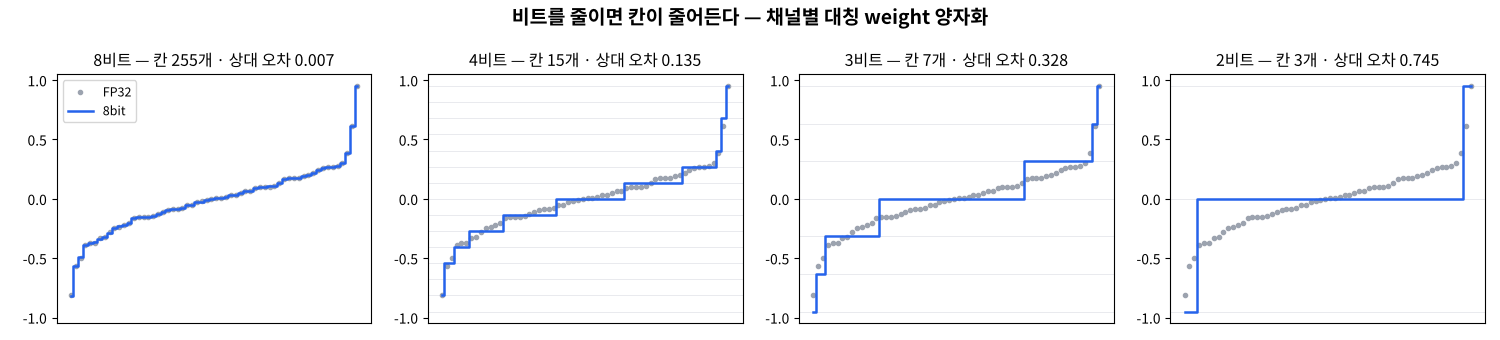

In [ ]:
#@title 🖼 그림 — 비트를 줄이면 칸이 줄어든다 — weight-only PTQ 8 → 2비트
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day4/img/f1_bits.png", embed=True, width=860))

**✍️ 직접 구현 1-1** weight 텐서를 **출력 채널별 (axis 0) 대칭** `bits` 비트로 양자화했다가 되돌린 텐서를 돌려주는 `quant_weight(w, bits)` 를 만드세요 (Day 1 의 식, PyTorch). qmax = 2^(bits−1) − 1, scale = 채널별 |w| 최댓값 / qmax 입니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 1-1 — 실행할 때마다 하나씩
show_hint("1-1", "7LGE64SQ67OEIOy1nOuMk+qwkjogYHcuYWJzKCkuZmxhdHRlbigxKS5hbWF4KDEpYCDihpIg66qo7JaR7J2EIGAoLTEsIDEsIDEsIDEpYCDroZwgKGB2aWV3KC0xLCAqWzFdICogKHcuZGltKCkgLSAxKSlgKSDrsJTqv5Tslbwg64KY64iX7IWI7J20IOyxhOuEkOuzhOuhnCDrkKnri4jri6QuHnFtYXggPSBgMiAqKiAoYml0cyAtIDEpIC0gMWAsIHNjYWxlID0gYW1heCAvIHFtYXguIDAg7Jy866GcIOuCmOuIhOyngCDslYrqsowgYGNsYW1wKG1pbj0xZS04KWAuHmB0b3JjaC5jbGFtcCh0b3JjaC5yb3VuZCh3IC8gc2NhbGUpLCAtcW1heCwgcW1heCkgKiBzY2FsZWAu")

In [ ]:
# ✍️ 직접 구현 1-1 — 채널별 대칭 weight 양자화 (quantize → dequantize)
def quant_weight(w, bits):
    # TODO
    pass

w0 = rn20.layer1[0].conv1.weight.detach()
for b in [8, 4, 3, 2]:
    print(f"{b}비트: 서로 다른 값 {len(torch.unique(quant_weight(w0, b)[0])):3d}개 · 상대 오차 {((quant_weight(w0, b) - w0).norm() / w0.norm()):.4f}")

In [ ]:
_w = torch.tensor([[1.0, -0.5, 0.26], [0.02, 0.01, -0.03]])
_q = quant_weight(_w, 3)
assert torch.allclose(_q[0], torch.tensor([1.0, -2 / 3, 1 / 3]), atol=1e-6) and torch.allclose(_q[1], torch.tensor([0.02, 0.01, -0.03]), atol=1e-6)
assert len(torch.unique(quant_weight(w0, 3)[0])) <= 7
print("✅ 채널별 대칭 양자화 — 3비트면 한 채널에 값이 7개뿐")

In [ ]:
#@title 🔒 정답 보기 1-1 — 강사가 알려 준 실습 1-1 잠금 코드를 입력하세요
show_answer("1-1", (
    "CeWrcIBS40xhOaTV6fh+iAkHWsdO/mzzKXWAY6yEpV2TM+Y9soMyCT6xtg/uUR3lKZ5n839QAsfQGOA7b41k9t3p"
    "CcRxbBERIKyWxHg1OVOLTjG6gFAuIaDklkBtUOlgu4DOFJdBen0I4jMj5fxS/P4K4V46B3XQAt3U5cUZdvMZ0Yj9"
    "QxwmfCpcpgEsp1g0KHGV0TfoyvMJGVrvkVNKbr4N0Zjz51iwlxTdkDXbSsFcYX8XDghsbxkFcoa+6bGIlJ7fEEV0"
    "AXzofXmLpeEomJQcw9u+oS9iKWxXrXvOPOuKvO1bkViX53fgHQQW1bYEb+cftiJLDhgcvFWEF71AOJ0/Suj+MMUJ"
    "leyACX3PC2A0Uwn3kYBdullWDs4xit+C8hGNMP98b+UJga0bhzV4ERLuHYRd/SaghC0zqjZAj11qOsFJvBE0IW2e"
    "HzFekZHKSJySiFlCdtkHQCSOk5ucx+qfypHz3UoOGr6fCI5OXmgOkmCj14MaykHSa3S7bDID3s42KWV9JVOdH4Rd"
    "iUyirNxZfnMlyewLwABfAP01khSoa0eilc6evT+eLrqZhUqifSQQUI5C0n/fDY5SDfOb2B+P7hbqyUbhGiRsT6oS"
    "3fjOG+SGAk/Jme8s1cev9hxBwfJO/cLXk+DiEM+Y8Dkl+jUqMUlIJVpZwC/Hb/93+anCs5mKQE6oOYQLi1NNmds4"
    "yMR7yeE3uEwUaLXxrun4Ai0xqEN7vH6fnj+80Cuof6JslGf8cIQVdsnRnBTr4+6RqpB0ws9KwrSx73jTYTQXmHmg"
    "G8QA3Ghi0GKz2u4+1iZsxayeHAIwKSaIh1D4Wr7pmr1wzOihXw9ZJ79jfsbAmBqfIFhRlL2nXA+mECjxcneR2SSM"
    "RYGngDQg2f5KnZSGZanhAC2ldaGOJ2WGonrMXWCqLFSkFvkmXL00nN3+eq2nTt8gLih4izXaRq+mTC0X3kOimIAl"
    "d0mDXJXULEU0rt/Lw6izWkv+nRcdue0YtWn+E4Jm0VCg2jbasfbgdABc283amHpU1bL43ucSX7KhfJr69fTmyqNt"
    "L2koA8VxPbmOuX+mTNzemBHsmnikrjE="
))


**✍️ 직접 구현 1-2** `rn20` 을 복사해 모든 Conv · Linear 의 weight 를 `quant_weight` 로 바꾼 **weight-only PTQ** 모델의 정확도를 8 · 6 · 4 · 3 · 2비트에 대해 재서 `wq_df` (열 `bits`, `acc`) 로 정리하세요 (활성값은 FP32 그대로).

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 1-2 — 실행할 때마다 하나씩
show_hint("1-2", "67mE7Yq466eI64ukIGBtID0gY29weS5kZWVwY29weShybjIwKWAg66GcIOyDiCDrs7Xsgqzrs7guHmBmb3IgbW9kIGluIG0ubW9kdWxlcygpOiBpZiBpc2luc3RhbmNlKG1vZCwgKG5uLkNvbnYyZCwgbm4uTGluZWFyKSk6IG1vZC53ZWlnaHQuY29weV8ocXVhbnRfd2VpZ2h0KG1vZC53ZWlnaHQsIGIpKWAg4oCUIGB0b3JjaC5ub19ncmFkKClgIOyViOyXkOyEnC4e7KCV7ZmV64+E64qUIGBhY2NfdG9yY2gobSlgLCDtlokg7IKs7KCE7J2EIOuqqOyVhCBgcGQuRGF0YUZyYW1lYC4=")

In [ ]:
# ✍️ 직접 구현 1-2 — weight-only PTQ 비트 다이얼
rows = []
# TODO: 8, 6, 4, 3, 2 비트
wq_df = pd.DataFrame(rows)
display(wq_df)

In [ ]:
_a = wq_df.set_index("bits").acc
assert list(wq_df.bits) == [8, 6, 4, 3, 2] and _a[8] > 0.84 and _a[4] > 0.8 and _a[3] < _a[4] and _a[2] < 0.3
print(f"✅ 8비트 {_a[8]:.3f} · 4비트 {_a[4]:.3f} · 3비트 {_a[3]:.3f} · 2비트 {_a[2]:.3f} — 4비트 아래에서 급격히 무너진다")

In [ ]:
#@title 🔒 정답 보기 1-2 — 강사가 알려 준 실습 1-2 잠금 코드를 입력하세요
show_answer("1-2", (
    "4dQ1IZKoUrjqslejznisgltkxjkXIwC//fyAoVs7IVnvlpVVdb9sC1ZXuoCE8CTf4mKL6OtlBiqIZaOmF8Ads6Za"
    "WS3Brbly1s6p1g/uGIORx8efADuHM/mIqF3rkSTGLV5Ynv+E+Ck963esnrWFiwlI/MpEnnmLCzt2wyTf+XhP69T/"
    "asBAXjmR4KkSomFiUbkeKqIyk4CcrdRrcoiiofa9chMhhpoNKXAztIIqom3Sr3l3EgEiKXkYTiE+bqn2EAdgJaDS"
    "QG8RxVozP5DFLQUpEMsHMlCnY0RvOMojPCy0GAVfCxFD2EKhERN9FD7ak/12ytnUBK/ZZ+U3OkoJnwyhbFABUEOg"
    "uRNzTC4otxyayxYtJ/lX8p82bCUFYmn5lmkv61ab/n9/aTMUCMAMiFA/quJm01dtjuTfy/QQLEO2LzoYiBJgB5YM"
    "imd1wxs2c/mz3URiuYSw1kW5fC5GUhZxnEVNofLJcC4P7Yq4gJMTqA4AwYnysRaRqXwpxV3IYxILeqkqR+Chgo9x"
    "DuQX0GCge6FcaZcxj3dgWGVVQQo7Gdmh6JnkZKSVHgaA/SV99QskakfxC3ZhAszNDpdOCZEgGAYZiVjbo1ODkX+O"
    "v64DRAkuwXbB7LB0gbZd2ELm7r2h5kg7ZEIPkBeEcTwGid/MMyqFSQnftAIWEohjC6yM6cLamxqQxU3t2wM8/qv3"
    "Sp0aExQH5oDI5VOVPX1JdPHhE/n99ywY2RTdthjjf0RsoULawrniIX5lUijCWVkLczzkIi2biOMeKIKzM9+NdZKq"
    "TeHfqLABPZtc3nn1qKJTyQbY34O16N5f4glQhSFkitb6o6Sl0/aC9sfM5zHOfkbYf6ysbIUG5fCsyOwXq2UwlI/g"
    "QhlLsNuxTGsant01+n7nsglSb2f4vsgZKO6tOB/r5BzqIDnbxDFbJgA4qZ8f3EZRzWhVZhftcJdO4dsraXmJrRqX"
    "zxYW5cdlIoOXBZeeICHbH6pWqHcnbgCec9WNszAa1G84I2PFfDzvadbWrMAuifF4apza9AQvGHN+"
))


**▶ 예제 1-A (제공 코드 — 실행만)** 오늘의 비교 기준선입니다. `rn20` 을 **배치 1 고정**으로 `rn20_b1.onnx` 에 내보내고 (`export_b1`), Day 3 의 TensorRT 용 PTQ (`make_trt_int8`) 로 `rn20_ptq8.onnx` 를 만들어, FP32 · ORT PTQ INT8 의 정확도 (`onnx_acc`) 를 `base_df` (열 `model`, `acc`, `size_kb`) 로 정리합니다. 1-2 에서 3비트는 무너졌습니다 — 8비트 PTQ 는 어떨까요?

> 이 셀은 **직접 구현이 아닙니다.** 그대로 실행하고, 출력과 아래 해설을 읽어 보세요.

In [ ]:
# ▶ 예제 1-A — 제공 코드 (그대로 실행)
export_b1(copy.deepcopy(rn20), "rn20_b1.onnx")
with quiet():
    quant_pre_process("rn20_b1.onnx", "rn20_b1_pre.onnx")
make_trt_int8("rn20_b1_pre.onnx", "rn20_ptq8.onnx")
base_df = pd.DataFrame([{"model": "FP32", "acc": onnx_acc("rn20_b1_pre.onnx"), "size_kb": size_kb("rn20_b1_pre.onnx")},
                        {"model": "ORT PTQ INT8", "acc": onnx_acc("rn20_ptq8.onnx"), "size_kb": size_kb("rn20_ptq8.onnx")}])
display(base_df.round(4))

In [ ]:
_b = base_df.set_index("model")
assert abs(_b.acc["FP32"] - 0.846) < 0.002 and _b.acc["ORT PTQ INT8"] > 0.835 and trt_check("rn20_ptq8.onnx")["ok"]
print(f"✅ 8비트 PTQ {_b.acc['ORT PTQ INT8']:.4f} (FP32 {_b.acc['FP32']:.4f}) — 8비트에서는 PTQ 로 충분")

> 💡 **예제 1-A 해설** — Day 3 실습 4-1 과 같은 S8 대칭 PTQ 입니다. 8비트에서는 손실이 0.3%p 정도라 QAT 를 할 이유가 거의 없습니다 — 8교시 대결에서 다시 확인합니다.

#### 📌 1교시 정리

- 8비트 PTQ 는 ResNet-20 에서 손실 0.3%p — **충분**. 3비트 weight 에서는 PTQ 가 크게 무너진다.
- QAT 는 '이미 학습된 모델 + 양자화를 끼운 짧은 fine-tuning' — 저비트 · 작은 모델 · depthwise 에서 효과가 크다.
- outlier 모델 (Day 3 BadQuantNet) 은 QAT 로도 잘 안 고쳐진다 (강사 실험: 0.30 → 0.50) — 원인에 맞는 처방을 고른다.

## 2교시 — Fake Quantization: 학습 그래프 안의 양자화

학습은 FP32 로 해야 기울기가 흐릅니다. 그래서 QAT 는 정수 연산을 하는 대신 **양자화했다가 바로 되돌린 FP32 값**을 씁니다.

```
x  →  q = clamp(round(x / s) + zp, qmin, qmax)  →  x̂ = (q − zp) · s     ← fake quant
```

- **forward**: x̂ 는 FP32 지만 2^bits 개의 값만 가진다 → 모델은 '양자화된 세상' 을 본다.
- **저장**: weight 는 FP32 로 계속 학습 · 저장된다 (진짜 INT8 은 배포할 때 만든다).
- weight 는 **채널별 대칭** (scale 을 매번 다시 계산), 활성값은 **텐서 하나 · 비대칭** (보정으로 정한 범위 고정).

> 🎬 **애니메이션** [D4-2 fake quant](https://imguru-mooc.github.io/AI_CAMPUS/QP-day4/animation.html#d4-2)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

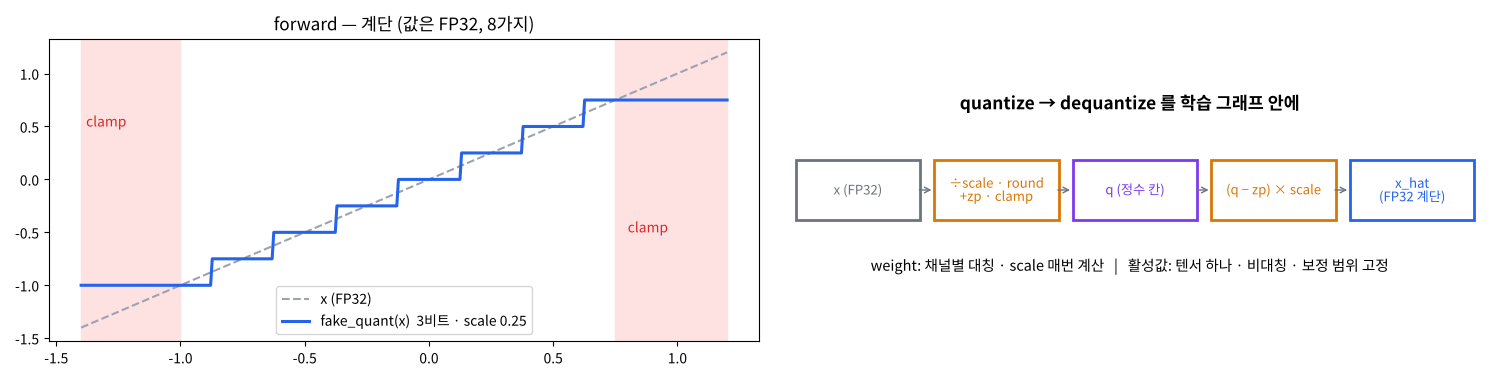

In [ ]:
#@title 🖼 그림 — fake quant = quantize → dequantize — forward 는 계단, 저장은 FP32
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day4/img/f2_fakequant.png", embed=True, width=860))

**✍️ 직접 구현 2-1** `fake_quant(x, scale, zp, qmin, qmax)` 를 만드세요. Day 1 의 `quantize` → `dequantize` 를 한 번에 하는 함수로, 입력 · 출력 모두 `torch.Tensor` (FP32) 입니다. (기울기는 3교시에서 다룹니다 — 지금은 `torch.round` 그대로)

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 2-1 — 실행할 때마다 하나씩
show_hint("2-1", "RGF5IDE6IGBxID0gY2xhbXAocm91bmQoeCAvIHNjYWxlKSArIHpwLCBxbWluLCBxbWF4KWAsIGB4zIIgPSAocSDiiJIgenApIMK3IHNjYWxlYC4eUHlUb3JjaCDroZw6IGB0b3JjaC5jbGFtcCh0b3JjaC5yb3VuZCh4IC8gc2NhbGUpICsgenAsIHFtaW4sIHFtYXgpYC4=")

In [ ]:
# ✍️ 직접 구현 2-1 — fake quant (아직 STE 없음)
def fake_quant(x, scale, zp, qmin, qmax):
    # TODO
    pass

x = torch.linspace(-1.2, 1.2, 9)
print(x.numpy().round(2)); print(fake_quant(x, 0.25, 0, -4, 3).numpy())

In [ ]:
_y = fake_quant(torch.tensor([-1.2, -0.3, 0.0, 0.13, 0.9, 5.0]), 0.25, 0, -4, 3)
assert torch.allclose(_y, torch.tensor([-1.0, -0.25, 0.0, 0.25, 0.75, 0.75])) and _y.dtype == torch.float32
_u = fake_quant(torch.tensor([0.0, 1.0, 2.0]), 2 / 255, 0, 0, 255)
assert torch.allclose(_u, torch.tensor([0.0, 1.0, 2.0]), atol=1 / 255)
print("✅ 계단 모양 FP32 — 범위 밖은 끝 칸으로, 범위 안은 가장 가까운 칸으로")

In [ ]:
#@title 🔒 정답 보기 2-1 — 강사가 알려 준 실습 2-1 잠금 코드를 입력하세요
show_answer("2-1", (
    "ITom/ciOePmwLKmOLmSPIgNj28GX2gptxnVOtyycM50cqUlcDJM5upomC26Zx+5g+iytcfy6YaBpkdYxgapVgu/Z"
    "eWGpJt6D8TXUtsQs7lQRXlkhiVyJ5QMFDh454Krxo0+jJD6Bt/JKrHv8whiMa57jjd4T6pW45UKuclIVJDYv1h8z"
    "5YRnsXmxd7QkX1MY4Tgf7OGV//daJ3fQNFv3cZ0vkmawwxHffEEUiO+i4bC9o6ldwxYekpqWYQUyH9BvUzhnOXR2"
    "FjqFLSwBtYRNSLNwJ/dUpDa3WowIKePHf7LmgTJV3siEznz8e+wF3gVf6+ernGNQGafZE4IiLXIlF/JtjI3wlxMJ"
    "aoITw21ZcPCjvJR4FJc7ql8H+5/HElCCG5N3M6Zoe2XIXCM96Uh1ohmgqKuUE9n5ywg7+ZWiWDbhWs+f2nZkDpqq"
    "Xyt79DMMBbwGIstxDOSo4ptg5Ak5J4a4dBHeqFYQonK7H9yVaopIAuofpBjaDZMJFq/1kRLEGnx1eXyBN+a2Q7qK"
    "G1Hwy6p6NwJ+ZqbTQBWhT7HyflVZ8WfW8QJxj53cGoybpS3IVWIGhONWbtIjwAYjPvjQj57dxq0bV/yivW8RzO7K"
    "kaijLRsf1awTt0F/+eOhTseNexBT9o5lNjDi8eEmCUSIcMTD1BxqzeI2vqCQ1p/9EgRWYyI+DONK3gKoN6XPPVhX"
    "fyMhA17WoOPhFscPY4Rzopxm"
))


**✍️ 직접 구현 2-2** `FakeQuant(nn.Module)` 의 `forward` 를 완성하세요. 아래 시작 코드에 생성자 · 보정 모드가 있습니다.
- `per_channel=True` (weight): 채널별 |x| 최댓값으로 대칭 scale 을 **매번** 계산 (qmin = −qmax).
- `per_channel=False` (활성값): `self.calib` 이면 `lo` · `hi` 만 갱신하고 x 를 그대로 돌려줌. 아니면 0 을 포함한 범위 [min(lo, 0), max(hi, 0)] 로 **비대칭** (0 ~ 2^bits − 1).

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 2-2 — 실행할 때마다 하나씩
show_hint("2-2", "d2VpZ2h0IChwZXJfY2hhbm5lbCk6IDEtMSDqs7wg6rCZ7J20IOyxhOuEkOuzhCBhbWF4IOKGkiBgZmFrZV9xdWFudCh4LCBhbWF4IC8gcW1heCwgMC4wLCAtcW1heCwgcW1heClgLiBhbWF4IOuKlCBgeC5kZXRhY2goKWAg66GcIChzY2FsZSDsnYAg7ZWZ7Iq1IOuMgOyDgeydtCDslYTri5gpLh7rs7TsoJUg66qo65OcOiBgc2VsZi5sbyA9IHRvcmNoLm1pbmltdW0oc2VsZi5sbywgeC5kZXRhY2goKS5taW4oKSlgLCBoaSDrj4Qg6rCZ7J2AIOyLneycvOuhnCwg6re466as6rOgIGByZXR1cm4geGAuHu2ZnOyEseqwkjogYGxvLCBoaSA9IG1pbihmbG9hdChzZWxmLmxvKSwgMC4wKSwgbWF4KGZsb2F0KHNlbGYuaGkpLCAxZS04KWAsIHFtYXggPSAyXmJpdHMg4oiSIDEsIHMgPSAoaGkg4oiSIGxvKSAvIHFtYXgsIHpwID0gcm91bmQo4oiSbG8gLyBzKS4=")

In [ ]:
# ✍️ 직접 구현 2-2 — FakeQuant 모듈
class FakeQuant(nn.Module):
    def __init__(self, bits=8, per_channel=False):
        super().__init__()
        self.bits, self.per_channel = bits, per_channel
        self.register_buffer("lo", torch.tensor(0.0)); self.register_buffer("hi", torch.tensor(0.0))
        self.calib = False

    def forward(self, x):
        # TODO: weight (채널별 대칭) / 보정 모드 / 활성값 (텐서 하나 · 비대칭)
        pass

fq = FakeQuant(8); fq.calib = True; fq(torch.tensor([-0.5, 2.0])); fq.calib = False
print("범위", float(fq.lo), float(fq.hi), "| 출력", fq(torch.tensor([-0.5, 0.0, 1.0, 3.0])).numpy())

In [ ]:
_f = FakeQuant(8); _f.calib = True; _f(torch.tensor([-0.5, 2.0])); _f.calib = False
_o = _f(torch.tensor([-0.5, 0.0, 1.0, 3.0]))
assert abs(float(_f.hi) - 2.0) < 1e-6 and abs(float(_o[1])) < 1e-6 and abs(float(_o[3]) - 2.0) < 0.01 and abs(float(_o[2]) - 1.0) < 0.006
_w = torch.randn(4, 3, 3, 3); assert len(torch.unique(FakeQuant(3, True)(_w)[0])) <= 7
print("✅ 활성값: 보정 범위 [−0.5, 2.0] 고정 · 0 은 정확히 0 · 범위 밖 3.0 → 2.0 | weight: 3비트면 채널당 7개 값")

In [ ]:
#@title 🔒 정답 보기 2-2 — 강사가 알려 준 실습 2-2 잠금 코드를 입력하세요
show_answer("2-2", (
    "tDhFzAquURGAMPXxoBQzXAUyfOLOiHYV7Hlq+F4TA3O/qRYU0Skp9bDCa1PCzcb3HWDrnSu89gklixnXDj3suAoo"
    "GKQvqyhmMsi8YMLQuWfKVWmmn8A4tODS0ISkVv4khkJycOOuSNdPF/DsBYi3gA7RZML8SEYSHethUFu4aQATncrP"
    "DOfDK/d08AIxUnZ/x+f0fCQcZIpNZ94t5ifKg+045Qpmp0FYgSW8s+bb2dFaBtgpS9bapIV8ziHb0edJSLUDhapN"
    "uA9zrIo5Yb4QBr+F6RBevF+FbumtbbDlEmQ0M5vkxN2yCpn5vXngroGHPKbEfcSqvzu5JOSs8/Z9tlyLXNTxUR+3"
    "f68FsZ5GrjlQsS0cgnD86lqkkk5RZpp6jfSbdiIwyk6QvM+/tFVsGGA+rSNwegs3C6qoP00HMR/Qg64phmGFnx6V"
    "902RMRYxolRR21ajtuMSexJbUjStMYdadMAFMZ5wpImmYaOBTcHA+m+dBZH02dWK3W1NqiqiEPRy6OeZPb986u+j"
    "zsknP8kx6p181aVn5Ezt8HLR7u+uEHyW8NlubO8uwRqDnRVL5MeCIhXqdtMZ1H2+5xVggh7SZMJP9/iMvjTeOrcx"
    "DTN38MYFPJDr5e8tNWXdKTsFrhpLNeaI3EWJDIqeS6ybMCfDQfVjCiWV6eXNRAD6FYo6Us31sKx2su9IUiPP8qvt"
    "7Ty6WXkvWstnpwcYQu0A5Pi/GkOv3IKrTFMh7gTcm7mEnTkTtaVLSG+oOcV+MC2se20shzGC+syE9Bgc/nmweZh3"
    "+LRuoFgLMP+rXpwieOzDYAB+qMCDKUUbvUtRB4gSCbDvuo/a5Gl6TbKfNn9VGYcAi9gExpC4k1iy8iJt8ZolDqDY"
    "yXOhsmeo0lYqPCiQGSrE2toeenIeRbR9XK5YS/0INSirCNoPQb0e31K2w9YY1rwKN0txExvastLqbzIjBctoSgkT"
    "l8gLBpnaHaM3fahnSXD2xIfTqC0JTmY203rWHbkTYVReLT4OjxR0DNXzKW54/nvCicwYbXo4Xx/2uG7CWlUY6Cxw"
    "X9ukSM74X3/9oy8jkytEgoPQgNx2HcxLXQ3rYLUv8x5m6lNUyo8MaI2yulC28Ait345WMHFlFsCA6FpEdUvq2Kwq"
    "2ubI2IPuJDCag+VToDGdNJ+p761mlPdwfHYidc83k/eRy9djmPEvo9Aas2VdMgJHnQWRPNk80biOJhFE13hEk+xV"
    "vLHVjesco3eZyLXxL78SzxVh64/Eful1Dr4uJfIaP71tN9KNG6XsF2rhOr14Tz7zJK6qhL6vfKKppBHrbWRKYLm9"
    "Kcl8/TSPGmYY0Ai1y5OAa7mFPiTfRe1CMgzYewSCi3Wf9BjaQEihGrmnPnpFYodObheBhgQ3BwFc+ZCGWbnJLJbB"
    "UP3JOzDsaKP3cENEcA5MivnZV95lfWj7jdl13WcUkG1/j4AJuPvwjv1NVKgZ5jF4pABK6y6Oxe7PJSiVYRKm06QT"
    "fi7TbEr/xNLfj2ej3lkxJ0hDx7XuzfdmS1OH/YTUY7H4Jbs3h+cPTthJ87jiGW/mj4iLqIulNc8sRQGtCi7SuRsh"
    "Pw6bpKiLCK9LaoES9EU8R0Dhk/ke9jM/zcBn92JmoYGOONsjBhXNXt2y87jtTlETxHUc/j3uTH6iAY3rI/WBcYRU"
    "hMDrdsWrJhSQVdHbI1dohzoqT52d118r84pxajGZYX7DzNEqF6J+jsr0dU8RiGtQDyIFAgm+pxoLXnobaCTApe2U"
    "PsssE6OP03INjnebf21fAmly0/1ffDk2Zn4PaDnLu0uBqNn2/tql1mkXsJrw1hN7+BctN89V8OC5NaiIS86XX65g"
    "C7EZofyk+YB2KbyZN7xnCwVXW43BhQT8eZG3HwBaED5eX8ScVmGrcmFNfIkQDZ7h1lggouxjt0LKtYGRSRO9Zt8N"
    "5BORstUrgPafpTMsfMadp4fqOZFSs6/u4FTa6KfjxHp2MBw2Sr+mvCcSmJsfzm5UBZW3mW+eGBoUH2/F/SaDIZPB"
    "wkYkMqarYf3fFZXkVEb9UAN8jMLU8H5uYAJL3oUFhH+e5OrUh+y0eH3t+RtGRBCNyM91KsoT/uQ+kL7cGgUuhl/W"
    "d6TAxIWOetH95dFJ8W4Gpg9WcB92Eu0xZiSL017svjhg6/xTVfowPdX76LO9HadWkts6Et3xCybG1DbgOTSBgbIQ"
    "a1CdWMfywtJcukS9KVjUT3R+/cV3irBB2eBowvf0ZRT2uJHOMIY4OTEA5kE="
))


**▶ 예제 2-A (제공 코드 — 실행만)** 왜 STE 가 필요할까요? `w = torch.tensor([0.31, -0.77, 0.20], requires_grad=True)` 에 2-1 의 `fake_quant(w, 0.25, 0, -4, 3)` 를 적용하고 `((y - target) ** 2).sum()` (target = `[0.5, -0.5, 0.5]`) 을 역전파해 `w.grad` 를 `grad_round` 에 저장합니다. 실행 전에 예측해 보세요 — 기울기는 얼마일까요?

> 이 셀은 **직접 구현이 아닙니다.** 그대로 실행하고, 출력과 아래 해설을 읽어 보세요.

In [ ]:
# ▶ 예제 2-A — 제공 코드 (그대로 실행)
w = torch.tensor([0.31, -0.77, 0.20], requires_grad=True)
target = torch.tensor([0.5, -0.5, 0.5])
loss = ((fake_quant(w, 0.25, 0, -4, 3) - target) ** 2).sum()
loss.backward()
grad_round = w.grad.clone()
print("loss", float(loss), "| w.grad", grad_round.numpy())

In [ ]:
assert grad_round.shape == (3,) and torch.all(grad_round == 0)
print("✅ round 를 지나면 기울기가 전부 0 — 이대로는 weight 가 한 걸음도 움직이지 않는다")

> 💡 **예제 2-A 해설** — round 는 계단 함수라 평평한 곳의 미분은 0, 계단 경계에서는 정의되지 않습니다. 그래서 PyTorch 의 torch.round 는 기울기 0 을 돌려줍니다. loss 는 0 이 아닌데 기울기가 0 → 학습이 멈춥니다. 3교시의 STE 가 이 문제를 풉니다.

#### 📌 2교시 정리

- fake quant = **quantize → dequantize** · forward 는 계단, 값은 FP32, 저장도 FP32.
- weight 는 채널별 대칭 (매번 scale), 활성값은 텐서 하나 · 비대칭 (보정 범위 고정).
- 문제: **round 의 기울기 = 0** → 그대로는 학습이 안 된다.

## 3교시 — STE (Straight-Through Estimator)

아이디어는 단순합니다. **forward 는 round, backward 는 round 가 없는 것처럼** (기울기 1 을 그대로 통과).

```
forward :  y = round(x)
backward:  ∂L/∂x = ∂L/∂y            ← "곧게 통과 (straight-through)"
```

그리고 clamp 가 함께 있으므로, **범위 밖으로 잘린 값은 기울기 0** (clamp 의 기울기) — 범위 안의 값만 학습됩니다. PyTorch 에서는 `torch.autograd.Function` 으로 forward · backward 를 따로 정의합니다.

| | forward | backward |
|---|---|---|
| `torch.round` | 계단 | 0 → 학습 안 됨 |
| **STE round** | 계단 | **1 (그대로 통과)** |
| clamp (범위 밖) | 끝 칸 | 0 → 잘린 값은 학습 안 됨 |

> 🎬 **애니메이션** [D4-3 STE](https://imguru-mooc.github.io/AI_CAMPUS/QP-day4/animation.html#d4-3)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

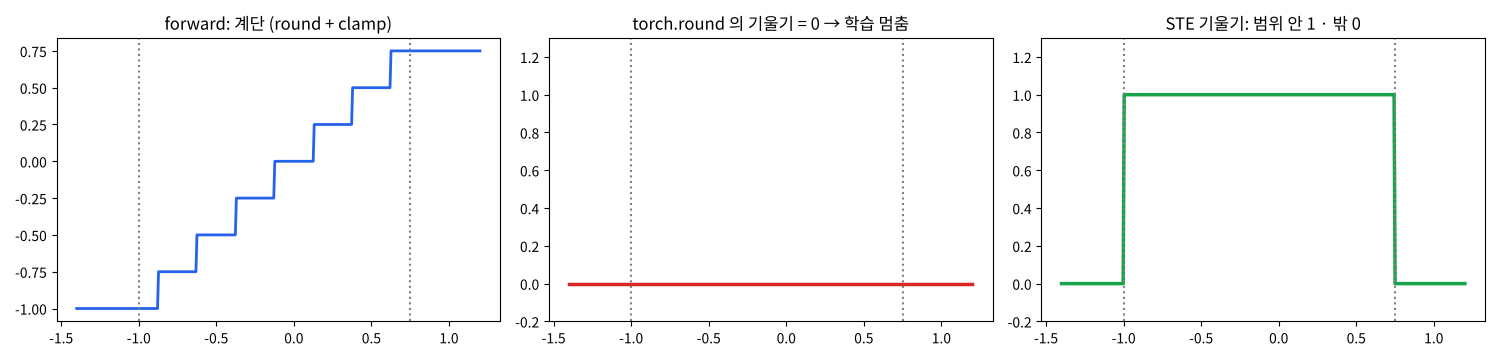

In [ ]:
#@title 🖼 그림 — STE — forward 는 계단, backward 는 곧게 통과 (범위 밖은 0)
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day4/img/f3_ste.png", embed=True, width=860))

**✍️ 직접 구현 3-1** `torch.autograd.Function` 을 상속한 `RoundSTE` 를 만드세요. `forward(ctx, x)` 는 `torch.round(x)`, `backward(ctx, g)` 는 `g` 를 그대로 돌려줍니다. 사용은 `RoundSTE.apply(x)`.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 3-1 — 실행할 때마다 하나씩
show_hint("3-1", "YGNsYXNzIFJvdW5kU1RFKHRvcmNoLmF1dG9ncmFkLkZ1bmN0aW9uKTpgIOyViOyXkCBgQHN0YXRpY21ldGhvZGAg65GQIOqwnC4eYGZvcndhcmQoY3R4LCB4KWAg4oaSIGB0b3JjaC5yb3VuZCh4KWAsIGBiYWNrd2FyZChjdHgsIGcpYCDihpIgYGdgLg==")

In [ ]:
# ✍️ 직접 구현 3-1 — STE round
class RoundSTE(torch.autograd.Function):
    # TODO: forward · backward
    pass

x = torch.tensor([0.2, 0.7, 1.5], requires_grad=True)
RoundSTE.apply(x).sum().backward()
print("forward", RoundSTE.apply(x).detach().numpy(), "| backward", x.grad.numpy())

In [ ]:
_x = torch.tensor([0.2, 0.7, -1.6], requires_grad=True); _y = RoundSTE.apply(_x)
(_y * torch.tensor([1.0, 2.0, 3.0])).sum().backward()
assert torch.equal(_y.detach(), torch.tensor([0.0, 1.0, -2.0])) and torch.equal(_x.grad, torch.tensor([1.0, 2.0, 3.0]))
print("✅ forward 는 반올림, backward 는 위에서 온 기울기 그대로")

In [ ]:
#@title 🔒 정답 보기 3-1 — 강사가 알려 준 실습 3-1 잠금 코드를 입력하세요
show_answer("3-1", (
    "Wrck6lTR2Pwt/QjX9ptX3CZkCJZv0ivwxEM99x/ovBgQtgZSGTARujwpHdikzSFylblzMZdjEFyabiInVlkTpuwP"
    "V99DVkHpK96eeQbrvVqD9hNGxi3esFbOeg9KhDkeZAedQhvSf2QbYjq73rPam8ntuTp93eTjslIfh2b4n3CZ2H5C"
    "KteJQ9I9rhG40TkaMim40IXlmUlTUyf6pQfqgMqBmkQzv2FyZqkWIzD0FjgKBXsN8nxM3b17P1stonrWOa5H5HPR"
    "9SJTJpm/SmNCyQRzhUs7LhGdgf9lZ3DjpQ3u6GPgxrZfxXmj3/12ELGPZudIYj6O+gjYrDq13tSL5MxF9MZt2hyJ"
    "PSkT9DIh07KqUUn9N4t6XZRl8OXUjtv28h0m6PTSuRglWR/Fgst/5ERJAUB7MhWeD2PGJpVZLj0vZPlEiR3wyb0r"
    "oFcgtqr8T3sd6xIChRaQf/lZ+vzILnN84exSWOqShhn0MskeNW5XpaFhYyA9tYVHCIv9aUxjDGLPSjp5hYQs10kq"
    "RcSJJboqUaW/UOoKaz/ioRkrGmpgHG8ToYIMv+kTubxSv9MdlTzrOjImdqsBYIXJaD7QjOCkm+iWUq/JMQGGrfWT"
    "nVAozTTEEJrwj3hywjHDU4Kk/kj+NB6983qNcGwVYt+ZtcE9pFR8TYGhnlXbMLTtOKi39DHT2hLwtW/u33iye3BH"
    "4H1J26t+DzTnBaiKKKCn4GNCulZZ5vVNZDSJ5Ww4/8i/Ny8qDQV+BUPhYIr4db2g0z/2MdGK6MVBnUnwITzVjLH9"
    "di0Tl17N1qq0YFFG30EZ3mU4s5TiPE0nuEJ6Y37/ez85a3vAt275hxtu0mgfAqEi6ev4eIIkXh3WMg/mFNNMBqHG"
    "ofPpOVChL8w5efJPwIMyq0Z6IqKfMTpaG7kyYcAWdl8sQoYQFEQzxB5d36KrsnH/8oeS8ybWXkVYXBePeL//C44Y"
    "sz2lRo8szAx0gOaaOfrRvfuk8ib5Z9u+QhS2hEFIQQ5p1rxkHqxmaRJBTiK8I6rPQ+FuCaQ/XAdJZhHi6Df4+PlV"
    "ag7FBgcj65w8kwFhKQxip5cxRxjSfXXqWC9Y"
))


**✍️ 직접 구현 3-2** `fake_quant` 를 STE 버전으로 다시 정의하세요 (`torch.round` → `RoundSTE.apply`). 그리고 `x = torch.tensor([-2.0, -0.4, 0.3, 0.6, 2.0], requires_grad=True)` 를 3비트 대칭 (scale 0.25, −4 ~ 3) 으로 통과시킨 합의 기울기 `g_ste` 를 구하세요. 범위 밖 값의 기울기는 몇일까요?

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 3-2 — 실행할 때마다 하나씩
show_hint("3-2", "Mi0xIOydmCBgZmFrZV9xdWFudGAg7JeQ7IScIGB0b3JjaC5yb3VuZGAg66eMIGBSb3VuZFNURS5hcHBseWAg66GcIOuwlOq/ieuLiOuLpC4eeCDrpbwg7Ya16rO87Iuc7YKoIOy2nOugpeydmCBgLnN1bSgpLmJhY2t3YXJkKClgIOKGkiBgeC5ncmFkYC4e67KU7JyEIFviiJI0wrcwLjI1LCAzwrcwLjI1XSA9IFviiJIxLjAsIDAuNzVdIOuwluydmCDqsJLsnYAgY2xhbXAg65WM66y47JeQIOq4sOyauOq4sCAwLg==")

In [ ]:
# ✍️ 직접 구현 3-2 — STE 버전 fake quant (같은 이름으로 다시 정의)
def fake_quant(x, scale, zp, qmin, qmax):
    # TODO
    pass

x = torch.tensor([-2.0, -0.4, 0.3, 0.6, 2.0], requires_grad=True)
# TODO: 역전파
g_ste = None   # TODO
print("기울기", g_ste)

In [ ]:
assert torch.equal(g_ste, torch.tensor([0.0, 1.0, 1.0, 1.0, 0.0]))
print("✅ 범위 안 기울기 1 · 범위 밖 (−2.0 · 2.0) 기울기 0 — clamp 가 잘린 값의 학습을 막는다")

In [ ]:
#@title 🔒 정답 보기 3-2 — 강사가 알려 준 실습 3-2 잠금 코드를 입력하세요
show_answer("3-2", (
    "S/QFa01hjOVinC8yCwN82GnY8j+Z/30wwx7Dx9E0U8QUpFlf7WuqVsqYJcMC1cEOrtPcldMiv1WBlOsbcRX/iIDo"
    "b36ZXrHr220MSUhPSG+s27Z9RBD3f0NYXr9zclzTl8rMqfv61x5lBC/d7dQhfHyhx8L0f5t/TM6c4ib+PRksCooY"
    "50bIL051Omo7KpWQzA5M24y+OJa91fpS4Nso+HDXwgZEy4IwYqfyEb+aBzl0MSaCgVjhYOzYLaLM+BGaz4rXt/+2"
    "xAPK8rhR/sVqkhT33chccbYpdQrwr7opjKfnE77X5gd8SnQyQDwu6fblUW1Kii2ijXnksZWNrAr1QJ/C8D8mfAWj"
    "XBHKgGp+06E5cJMZqWT35oghyTABfK1b8IQR/z9VAXUqWpWYC/bBNAGzv/5mrgXH1kfAhf921Qr4NDJFcGHV6fhA"
    "3ePop4yK0Sm5GL82gA+qUwhiLRMKd5nAqvzUV/yjyB5yRGXIXtUW8znAccmfIhL617vsvrxMrouxqc0eq/UWcz2a"
    "G2Y5u18B21Tm80Xyu/r4TLmVVFlhFcd0OGkdGeP8Sx0FEtBZFkEwyVngVrDyPfvS9IO0bJcwcTk/aADUxgILBtwl"
    "blz2iOCOnif//PqkPrbifdrlcsMA2J9EqomYTV8uP52dj/6e4JUbWUw/oz/IbBM3Fe7q8HIDHFKwE+cXPYLvTQaS"
    "fFQJroyRgIhHbo1cX/4tI9oSgpf1kj4viessO/Oe4NqIN7H7xTIxCfVI7ap9CJR2+d7PW2yMQVAHlnxPFovOm+Ou"
    "zrk+n15HCeg2RHibIJDzNvstIV8DQRFcHCnrYqksnKF2ULqlb3rReVnU+iSdmyABGUah6HegZKBcMGAgin38cacV"
    "92pov0nJanxfQLtUgBWET6zVfmT7DoEZ6BCG6OdmHkX4rI8vBleiB/nfCONpHHnJnoSnF3nugajMzaadzfUl+mAl"
    "TnKCnAbVyTM7NECW9OadRqqPGOv3D+/f9Mo0V2Ady+/IPzKb/+vndljwb5Lj19RfEUYjNmYiIFTXXkYj/P29ZsFJ"
    "QZ5NVXHJCbAmIFCprDUqDw3Sh25X5roWFyquKftdiyOSAQ=="
))


**▶ 예제 3-A (제공 코드 — 실행만)** 작은 실험: 3개짜리 weight `w` 를 3비트 fake quant 한 결과가 `target = [0.5, -0.5, 0.5]` 에 가까워지도록 SGD (lr 0.1) 로 50번 학습합니다. 3-2 에서 만든 **STE 버전** 으로 학습한 최종 loss `loss_ste` 와, `torch.round` 버전 (`fake_quant_round`) 으로 학습한 최종 loss `loss_round` 를 비교합니다.

> 이 셀은 **직접 구현이 아닙니다.** 그대로 실행하고, 출력과 아래 해설을 읽어 보세요.

In [ ]:
# ▶ 예제 3-A — 제공 코드 (그대로 실행)
def fake_quant_round(x, scale, zp, qmin, qmax):      # 비교용 — 기울기 0
    return (torch.clamp(torch.round(x / scale) + zp, qmin, qmax) - zp) * scale

def toy_train(fq, steps=50):
    w = torch.tensor([0.31, -0.77, 0.20], requires_grad=True)
    opt = torch.optim.SGD([w], lr=0.1)
    for _ in range(steps):
        loss = ((fq(w, 0.25, 0, -4, 3) - target) ** 2).sum()
        opt.zero_grad(); loss.backward(); opt.step()
    return float(((fq(w, 0.25, 0, -4, 3) - target) ** 2).sum()), w.detach()

loss_round, w_round = toy_train(fake_quant_round)
loss_ste, w_ste = toy_train(fake_quant)
print(f"round: loss {loss_round:.4f}  w {w_round.numpy()} | STE: loss {loss_ste:.4f}  w {w_ste.numpy()}")

In [ ]:
assert loss_ste < 1e-6 and loss_round > 0.1
print(f"✅ round 는 제자리 (loss {loss_round:.3f}), STE 는 목표 칸에 도착 (loss {loss_ste:.0e})")

> 💡 **예제 3-A 해설** — torch.round 버전은 기울기가 0 이라 w 가 처음 값 그대로입니다. STE 버전은 w 가 움직여 양자화 결과가 0.5 · −0.5 · 0.5 칸에 들어갑니다. QAT 는 이것을 수만 개 weight 에 대해 진짜 loss (cross-entropy) 로 하는 것입니다 — '양자화된 결과가 잘 맞도록' weight 가 칸 사이에서 자리를 옮깁니다.

#### 📌 3교시 정리

- STE = forward 는 round, backward 는 **기울기 1 그대로** (`torch.autograd.Function`).
- clamp 때문에 **범위 밖 값의 기울기는 0** — 잘린 값은 학습되지 않는다.
- STE 덕분에 '양자화된 결과' 의 loss 로 FP32 weight 를 학습할 수 있다.

## 4교시 — 직접 만드는 QAT

순서:

1. **BN folding 을 먼저** — 배포할 때는 BN 이 Conv 에 접힌 weight 가 양자화됩니다 (Day 2 3교시). QAT 도 **접힌 weight** 를 양자화하며 학습해야 배포와 같은 숫자가 됩니다.
2. Conv · Linear 를 **입력 FakeQuant (활성값) + weight FakeQuant** 가 붙은 `QConv2d` · `QLinear` 로 바꿉니다 (ONNX 의 QDQ 위치와 같음).
3. 보정용 500장으로 활성값 범위를 정합니다 → 이 상태가 **PTQ**.
4. 학습용 10,000장으로 **짧게 (3 epoch) · 작은 learning rate (1e-3)** fine-tuning → **QAT**.

| 설정 | 값 | 이유 |
|---|---|---|
| learning rate | 1e-3 (처음 학습의 1/100) · cosine 감소 | 이미 학습된 weight 를 조금만 옮긴다 |
| epoch | 3 | 대부분의 회복은 첫 epoch 에 일어난다 |
| optimizer | SGD momentum 0.9 · weight decay 5e-4 | VB Day 2 학습과 같은 설정 |

> 🎬 **애니메이션** [D4-4 직접 만드는 QAT](https://imguru-mooc.github.io/AI_CAMPUS/QP-day4/animation.html#d4-4)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

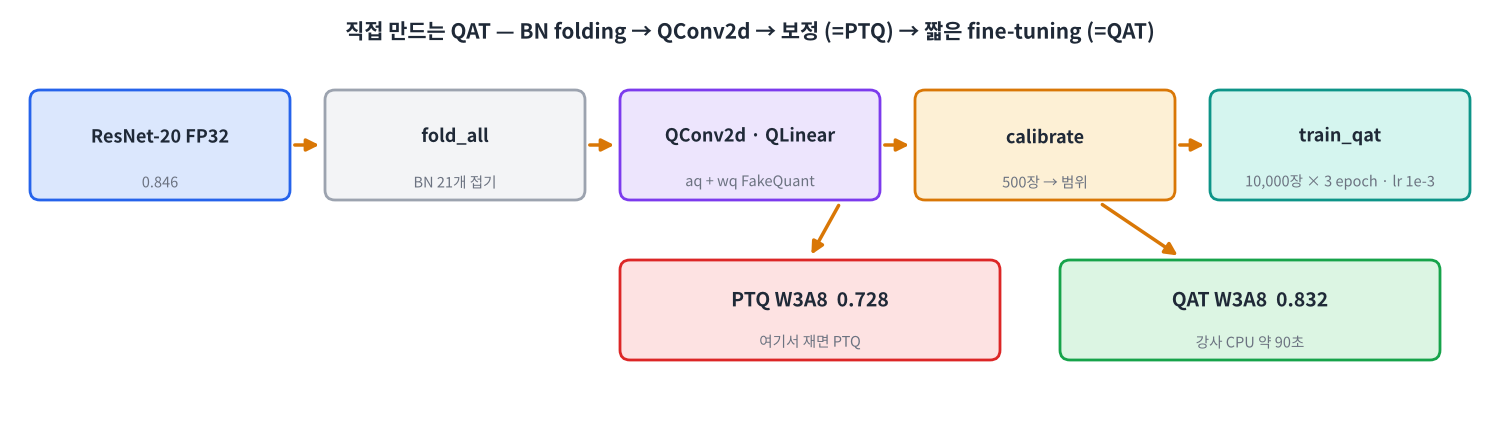

In [ ]:
#@title 🖼 그림 — 직접 만드는 QAT — BN folding → QConv2d → 보정 → 짧은 fine-tuning
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day4/img/f4_qat.png", embed=True, width=860))

In [ ]:
# QConv2d · QLinear — 입력(활성값) FakeQuant + weight FakeQuant 를 붙인 Conv · Linear (2교시 FakeQuant 사용)
class QConv2d(nn.Conv2d):
    def setup(self, wbits, abits):
        self.wq, self.aq = FakeQuant(wbits, per_channel=True), FakeQuant(abits); return self
    def forward(self, x):
        return F.conv2d(self.aq(x), self.wq(self.weight), self.bias, self.stride, self.padding)

class QLinear(nn.Linear):
    def setup(self, wbits, abits):
        self.wq, self.aq = FakeQuant(wbits, per_channel=True), FakeQuant(abits); return self
    def forward(self, x):
        return F.linear(self.aq(x), self.wq(self.weight), self.bias)

**▶ 예제 4-A (제공 코드 — 실행만)** Conv 와 BN 을 하나의 `nn.Conv2d` (bias 있음) 로 접는 `fold(conv, bn)` (Day 2 실습 3-1 의 PyTorch 판) 과, ResNet-20 의 stem · 모든 블록의 conv1/bn1 · conv2/bn2 · shortcut 을 접은 복사본을 돌려주는 `fold_all(model)` 입니다. 접은 뒤 BN 자리는 `nn.Identity()`.

> 이 셀은 **직접 구현이 아닙니다.** 그대로 실행하고, 출력과 아래 해설을 읽어 보세요.

In [ ]:
# ▶ 예제 4-A — 제공 코드 (그대로 실행)
def fold(conv, bn):
    k = bn.weight / torch.sqrt(bn.running_var + bn.eps)
    c = nn.Conv2d(conv.in_channels, conv.out_channels, conv.kernel_size, conv.stride, conv.padding, bias=True)
    c.weight.data = conv.weight.data * k.view(-1, 1, 1, 1)
    c.bias.data = bn.bias.data - bn.running_mean * k + (conv.bias.data * k if conv.bias is not None else 0)
    return c

def fold_all(model):
    m = copy.deepcopy(model).cpu().eval()
    m.stem = nn.Sequential(fold(m.stem[0], m.stem[1]), nn.ReLU())
    for blk in [b for layer in (m.layer1, m.layer2, m.layer3) for b in layer]:
        blk.conv1, blk.bn1 = fold(blk.conv1, blk.bn1), nn.Identity()
        blk.conv2, blk.bn2 = fold(blk.conv2, blk.bn2), nn.Identity()
        if isinstance(blk.shortcut, nn.Sequential):
            blk.shortcut = nn.Sequential(fold(blk.shortcut[0], blk.shortcut[1]))
    return m

rn20_f = fold_all(rn20)
print("BN 개수", sum(isinstance(x, nn.BatchNorm2d) for x in rn20_f.modules()), "| 정확도", acc_torch(rn20_f))

In [ ]:
assert sum(isinstance(x, nn.BatchNorm2d) for x in rn20_f.modules()) == 0 and abs(acc_torch(rn20_f) - acc_torch(rn20)) < 0.001
with torch.no_grad():
    assert float((rn20_f(torch.from_numpy(X_ev[:50])) - rn20(torch.from_numpy(X_ev[:50]))).abs().max()) < 1e-3
print("✅ BN 21개를 모두 접었다 — 정확도 · 출력 그대로")

> 💡 **예제 4-A 해설** — k = γ / √(σ² + ε), W' = W·k, b' = β − μ·k (원래 bias 가 있으면 b·k 를 더함). Day 2 에서는 ONNX export 가 해 주던 일을 직접 합니다. QAT 전에 접어야 'fake quant 가 본 weight = 배포 때 양자화되는 weight' 가 됩니다. ModelOpt 처럼 BN 을 남긴 채 QAT 하는 방법도 있지만 (5 · 6교시), 그때는 배포 도구가 접은 뒤의 범위 차이를 감수합니다.

**✍️ 직접 구현 4-1** `quantize_model(model, wbits, abits)` 를 완성하세요: `fold_all` 한 복사본에서 모든 `nn.Conv2d` · `nn.Linear` 를 같은 모양의 `QConv2d` · `QLinear` 로 바꾸고 (weight · bias 복사, `.setup(wbits, abits)`), 장치 `DEV` 로 옮겨 돌려줍니다. 그리고 활성값 FakeQuant 의 범위를 보정용 500장으로 잡는 `calibrate(model)` 을 만들어 **W3A8 PTQ** 정확도 `acc_ptq3` 를 재세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 4-1 — 실행할 때마다 하나씩
show_hint("4-1", "7J6s6reAOiBgZm9yIG5hbWUsIGNoIGluIHBhcmVudC5uYW1lZF9jaGlsZHJlbigpOmAg4oCUIENvbnYyZCDrqbQgYFFDb252MmQoY2guaW5fY2hhbm5lbHMsIGNoLm91dF9jaGFubmVscywgY2gua2VybmVsX3NpemUsIGNoLnN0cmlkZSwgY2gucGFkZGluZywgYmlhcz1UcnVlKS5zZXR1cCh3Yml0cywgYWJpdHMpYC4ed2VpZ2h0IMK3IGJpYXMg66W8IGAuZGF0YS5jbG9uZSgpYCDsnLzroZwg67O17IKs7ZWcIOuSpCBgc2V0YXR0cihwYXJlbnQsIG5hbWUsIHEpYC4g65GYIOuLpCDslYTri4jrqbQgYHN3YXAoY2gpYCDroZwg642UIOuTpOyWtOqwkeuLiOuLpC4eY2FsaWJyYXRlOiBgcGVyX2NoYW5uZWxgIOydtCDslYTri4wgRmFrZVF1YW50IOunjCDqs6jrnbwgYGNhbGliID0gVHJ1ZWAsIGBsby5maWxsXygxZTkpYCwgYGhpLmZpbGxfKC0xZTkpYCDihpIgYGZvcndhcmRfbG9vcChtb2RlbClgIOKGkiBgY2FsaWIgPSBGYWxzZWAu")

In [ ]:
# ✍️ 직접 구현 4-1 — Conv · Linear 를 QConv2d · QLinear 로, 그리고 보정
def quantize_model(model, wbits=8, abits=8):
    m = fold_all(model)
    # TODO: Conv2d → QConv2d, Linear → QLinear (재귀)
    return m.to(DEV)

def calibrate(model):
    # TODO
    return model

q3 = calibrate(quantize_model(rn20, 3, 8))
acc_ptq3 = acc_torch(q3)
print(f"QConv2d {sum(isinstance(x, QConv2d) for x in q3.modules())}개 | W3A8 PTQ {acc_ptq3:.4f}")

In [ ]:
assert sum(isinstance(x, QConv2d) for x in q3.modules()) == 21 and sum(isinstance(x, QLinear) for x in q3.modules()) == 1
assert 0.6 < acc_ptq3 < 0.8 and abs(acc_torch(calibrate(quantize_model(rn20, 8, 8))) - 0.846) < 0.006
print(f"✅ W3A8 PTQ {acc_ptq3:.3f} (W8A8 PTQ 는 0.84 대) — QAT 로 되살릴 출발점")

In [ ]:
#@title 🔒 정답 보기 4-1 — 강사가 알려 준 실습 4-1 잠금 코드를 입력하세요
show_answer("4-1", (
    "FX0pXc/ExY+AzA/D5l+4yW3ezO8cpyXeA2VOfe2uBw85EAOYDDqSbmZ7UiGanIGFqr0h5e5gXk5LqvgAn46DaYUP"
    "oLBerPiAeLAQgQQPNVU5DyEWUbQeQDZOASWtyJDhqtLWDmQJ8eV+NR3gWmcUJxQTvQetohbqsaVwa2aLZUjgDPDk"
    "VBRhzHHEQ9AYBd9poIVf+hHBW50SysyjgBFQpy0Ad+3Br9QM+Fct7Daa2gcsWLZh7fGCkjqBSlsBl4vmKJ8MuZDj"
    "GHFJCHvgt2XjUf3wVxl9DyDY8tOoXi8gqdJwdCzO6xHgCKLZFbWFYqxBor0lrWXwd6WSO1gLT4kjcRQT8r6UFUFX"
    "Jf6SUMTry55IBB3tQ8qbptXrE+uUxo9k9K/9mN563HW9+xZjKal19mZwkZ3QZWStBEAzYYojeTcvlajNqKb//VKj"
    "gHZwai5nNZe5brnehtXAVcq0rVz9jLOVVqQmJ6f1iO6rBLgnduzc8nrfxCWk34DVu0m2MMVYXYGqEpGM9GvQJZXT"
    "4X4YguXHcUwP58qsZGQlQZFcOUepLl4AzQeqqaE4nn6izhfAb4r9Za4+Hb0Tvdd2QYZ12wSauXDBHRsBohUQGyH0"
    "vHMPW4PRh8bmylTG+1Eg0pixcYIbeXL4G4Pzn7+duLm7lkHCCWD+hbuqaFRJrZ6buFYXyNQkkOGNKtD+Av/ppNq6"
    "r7NoG2xxdrekQWjN3FpTbBgGGDkqukWKFLztzHKjRS9DJf1YkBMn18US7kDJjBw9t73T8Du7IdGWxCRoXtwyJdOo"
    "WXkssMPtaHLcPQaWoYOytcpX+MGdUl+e8HvO4PuYpTHBFcLf3qyUA0cpTY0gTahpQI7wkDmsWzLZTZO4+zPnD4NZ"
    "pjbvxXthtjmfwlsQ8Pt7nnlxCshFmDhpQgMIWZZhYrzc9IrH62oKBrgyJenr84SHyPssAbFMgFKM9ZndGC0whV74"
    "EQhVH8jloNykbAj0drDOw96je19Z6Jt9pDJQTx4iYakvDY2N7m+axvc7kJNvR1uP+3DPcWOm+3n4vFB5l3wngTB0"
    "reQtl+27vlzTCEDLKBqrG+4U/9RWyFkIaORnKFBUxwuH4PhUoZrjN0IdRP8P4Y7RTLHlYA9ENgWhSynse5fI4iqD"
    "qmpOXzTbiOSULGbWUYwBvWwxnBqVZk7K5cbB84Dqv5EvwQCquQXo8pNDnJjbr0qlPVjnmjnRjO34qQV6Y44CCBYI"
    "B0528WugxDJStof5/Y5jhY+cNkOztybDWxt/0XT0xbEm16Zt7OOngaNcDeNpBYvsB2cExM4X/5dzsw5nQnZKDkXf"
    "MPECUW1MBF9rkbLXAf1n4tsTcIg3RV3NCaipeQDXd0EEoB58AtuL8Lpt5S3KhFeY9xoWAx6X7gTGDlh++fP+jgD5"
    "aN+zhy1Gm/hZeKOcSOZW7qq22J/pnNw2yJk3o1bhVl9HVdEHJnMVQMOh+8xcrBPxo+HEibGjmkQMOnGogjZiiDpG"
    "RQfDm0xdfUy2Qc0hzfV2e9Wo55E0qxKcSxpSAg/qB+3jBbulNxFh1wowu5JfnZdU3lB0B5UOzp5conr1+DQipE/k"
    "MFpMlmSXDM412KtbZKO97B7QqjbOnYD/Ncsx1zSiqr2IVGZyzWNG4YUjU76d6j4TPbabLDmCRNig2zANW5K6ykG8"
    "krC7y2wGwsIA/iIiNVz/xpP870c8KaRfWOthfIDBZ/qyUDa7MVAMp/hzwHpr2p60gJxqLirvWlrrJdZmAsSrmTvN"
    "cgLhnlZbOMaFjQD6VX2iolbldbMBgXxXFIH/Rk3NUVzs7NvxB3xp5vkSSvI1Q33itqmRkr+uzxIlji1xgq9ToVPV"
    "U79NfWPcHuWLTtqlU49x4e8XLMVhsNNSnJevZ3QtDsyICdEpy9FfjZQiKD59ets1WJrNr9w9XIHOtL9arP5aOrdm"
    "EpZ3aqXvZSLB9irRKi+0s/0jsBp5GeZu7tyh4PhLKaYwiKSAzgNOy/0gliuwiv52MsxW8S9jsRkmeiAeyF8JsYea"
    "gmbf"
))


**✍️ 직접 구현 4-2** QAT 학습 함수 `train_qat(model, epochs=EPOCHS, lr=1e-3, on_epoch=None)` 를 만드세요. SGD (momentum 0.9 · weight decay 5e-4) + cosine 감소, `batches(seed=epoch)` 로 학습하고 epoch 마다 `on_epoch(epoch, model)` 이 있으면 부릅니다. 걸린 시간 (초) 를 돌려줍니다. `q3` 를 QAT 해 `acc_qat3`, `t_qat3` 을 구하세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 4-2 — 실행할 때마다 하나씩
show_hint("4-2", "YG9wdCA9IHRvcmNoLm9wdGltLlNHRChtb2RlbC5wYXJhbWV0ZXJzKCksIGxyPWxyLCBtb21lbnR1bT0wLjksIHdlaWdodF9kZWNheT01ZS00KWAsIOyKpOy8gOykhOufrCBgQ29zaW5lQW5uZWFsaW5nTFIob3B0LCDsoITssrQgc3RlcCDsiJgpYC4eZXBvY2gg66eI64ukIGBtb2RlbC50cmFpbigpYCDihpIgYGZvciB4YiwgeWIgaW4gYmF0Y2hlcyhzZWVkPWVwKTpgIOKGkiBjcm9zc19lbnRyb3B5IMK3IHplcm9fZ3JhZCDCtyBiYWNrd2FyZCDCtyBzdGVwIMK3IHNjaGVkLnN0ZXAoKS4eZXBvY2gg64Gd7JeQIGBtb2RlbC5ldmFsKClgIO2bhCBgb25fZXBvY2goZXAsIG1vZGVsKWAgKOyeiOycvOuptCkuIOyghOyytCDsi5zqsITsnYQgYHRpbWUudGltZSgpYCDssKjsnbTroZwg64+M66Ck7KSN64uI64ukLg==")

In [ ]:
# ✍️ 직접 구현 4-2 — QAT 학습 루프
def train_qat(model, epochs=EPOCHS, lr=1e-3, on_epoch=None):
    # TODO: 걸린 시간 (초) 를 돌려준다
    pass

t_qat3 = train_qat(q3, on_epoch=lambda ep, m: print(f"  epoch {ep + 1}: {acc_torch(m):.4f}"))
acc_qat3 = acc_torch(q3)
print(f"W3A8 PTQ {acc_ptq3:.4f} → QAT {acc_qat3:.4f} ({t_qat3:.0f}초)")

In [ ]:
assert acc_qat3 > acc_ptq3 + 0.05 and acc_qat3 > 0.8 and t_qat3 > 0
print(f"✅ QAT 로 +{(acc_qat3 - acc_ptq3) * 100:.1f}%p 회복 — FP32 0.846 과의 차이 {(0.846 - acc_qat3) * 100:.1f}%p")

In [ ]:
#@title 🔒 정답 보기 4-2 — 강사가 알려 준 실습 4-2 잠금 코드를 입력하세요
show_answer("4-2", (
    "JU70YvyPH8eLnk6ISH1Kd92cKuAsAXc7eGBwLUJx+EsTUT41qGXRNW6rndRM2PMQswda5D2H3XVYk0A2Y6gqa+qI"
    "DzfStYx5cFKDl9hv8wocilHwgCz72yRBPZbWYbNgkBlJTyCG7MeV+Ct4ROFT7zbYC/SKGY3QXdgeEfCe59vmqtDj"
    "9+qzTE9FWmoaI8v7de5AOkbw2l/g2arsZleEkWNnkCBin8RyDmX+VRnYBRQpfLFC2wdf1R2PHfOW4M8nVUkR3cEE"
    "h/gTqCQnx7XOP7RP9tiepNLHOlC/woBYRYic1Vs3+rhbaM7Z3C192YqbJIS0WkPGP/QYGNBIF0CCap71GDE0yquG"
    "BpityYzgu3n6HfbpZsVeGY9azj3Z4p+cQM56WjPkJLR6FCH4XrX81N6Mxydwo0EPL8RiMMc9OAgLPMv/JZobtUTL"
    "LobU5ExM7rPRiizbr9D8YFXneNye7PC53Rkqj+6ZwuYUF2xI6UUJBNc8SHyNO+1KgrEx8T+muCpZKBXJKw0BIzwM"
    "81kzhHg7xuMAbExHJ8f9tSw9H/l59ot4KTqqPepl19oK7TBJF6BrL7NUETkbZojtNlNrcc13Z3Qdv3h7ucAbfMP2"
    "Q5jBlj+KM20j/At5fEIhsUQmaXYsJ3hynLk4f3MO5oukzz8foXh1vDZKf/LH0tMRk+1GbJ5PtaAhEa4uOlgDeQUQ"
    "ZRdtQXxzHdlidvXa0h9UTTZDwkFWm6/+gYZWrpTMfn08xNkMTaibeMIdWulRCgvt0MB+ehkvg2ASUSebuaNGgzuz"
    "v6UDLW0vYIFcprPK7WpPLbMG7IMdgQ8cdNYAjW1OU54cdBCQ9W0fjMzVHi/uPN1dQLpANHTIsGB8m0zNq6vIId9Y"
    "qOK7ugqax3D2365MS914jk45e9hcab0PuBCeCP2/pYWpv7+5pg2mgoTwDtJgZzIgfzi7kxgJrMPVhvKYmo5jdG38"
    "iHIvXdR7kuoP8rYqWfRlbZsSv0YuWQgx+MDgF7cphfZIXiOhr/lVL8RM5Mg1IZHBCLbLJCRj3qb9zX83Ih+x8xsn"
    "cqbxDmfxDyGEmF/RBWGTsI4CdjbsFDOVqgMRGPgg94cNQckZPspvS++Xjapi6R3XhekBjAlgjLPN8VCfcDrdBYBh"
    "R3gtG9sojbEzpRZsSYpj9fTahZnb92tjL65LNMPB5gCqEB8/ovFfNrJVmIaFpBvpgzJFGMTiPA963B39IiKM3NK6"
    "GYUi/XzhuuvMf6YjpRCmlEnOcRkc/99wRGXdiyGtRsLddoQfOpRcD+AsXqKEaoOJwdpC5so9LBRS/vBLDXlQy+iV"
    "7uW08vxbUi12YfA8g+l7+WMm5U9fHjW40xdmPIasX1HnnzaCEbGC9x5otB4eKB6yjksn/QX1D1lSNjUHCoxm8BY9"
    "WB4yATZpQpgpiRizvE+Ewl/pFyRaUU+e549ynbFP3isJ7KiZI/zUq5xnUFjudYxFdXYyAYRbKmgE65XPUKzr75wa"
    "nw+q9yUEaA=="
))


#### 📌 4교시 정리

- 직접 만드는 QAT = **BN folding → QConv2d (FakeQuant 2개) → 보정 (=PTQ) → 짧은 fine-tuning**.
- W3A8: PTQ 0.73 → QAT 0.83 (예시) — 3 epoch · lr 1e-3 로 충분.
- 학습 비용 (분) 도 결과의 일부 — 8교시 대결 표에 함께 적는다.

## 5교시 — NVIDIA ModelOpt PTQ

**ModelOpt** (`nvidia-modelopt`) 는 NVIDIA 의 모델 최적화 도구입니다. 오늘 직접 만든 일을 한 줄로 해 줍니다.

```python
import modelopt.torch.quantization as mtq
model = mtq.quantize(model, mtq.INT8_DEFAULT_CFG, forward_loop=forward_loop)   # 양자화기 삽입 + 보정
```

| 직접 만든 것 | ModelOpt |
|---|---|
| `FakeQuant` | `TensorQuantizer` (`input_quantizer` · `weight_quantizer`) |
| `quantize_model` (Conv 바꿔 끼우기) | `mtq.quantize` 가 Conv · Linear 에 자동 삽입 |
| `calibrate` | `forward_loop` 로 보정 (max calibration) |
| BN 먼저 접기 | BN 을 그대로 둠 (배포 때 TensorRT 가 처리) |
| 범위 · 비트 | **config** — `INT8_DEFAULT_CFG` : weight 채널별 8비트 · 입력 텐서별 8비트 · 대칭 |

ModelOpt 의 양자화는 **대칭 (zero_point 0)** 이라 TensorRT 가 그대로 받습니다 (Day 3 4교시).

> 🎬 **애니메이션** [D4-5 ModelOpt PTQ](https://imguru-mooc.github.io/AI_CAMPUS/QP-day4/animation.html#d4-5)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

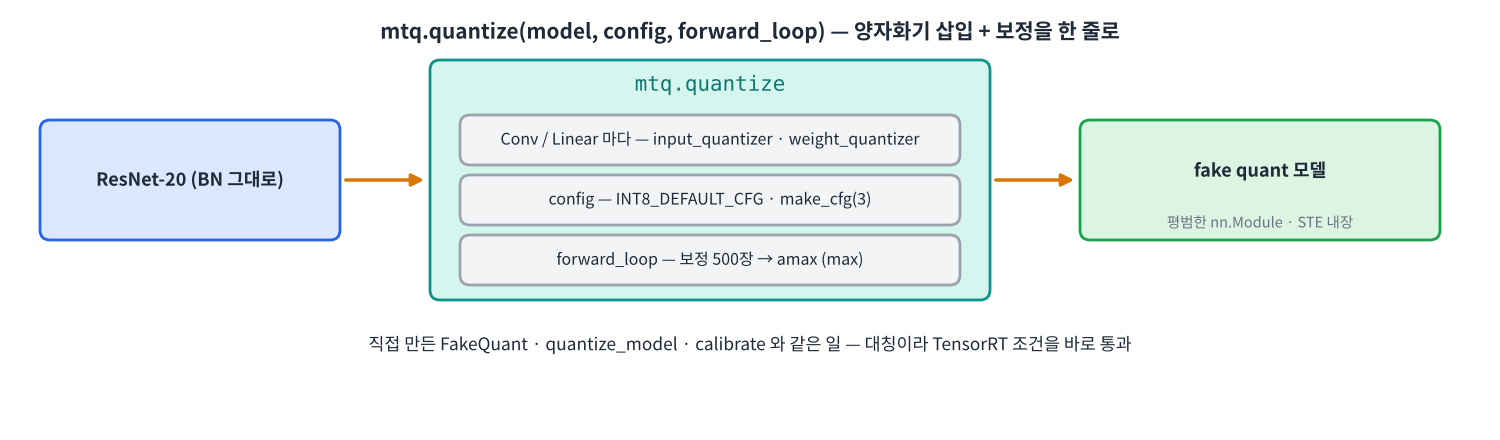

In [ ]:
#@title 🖼 그림 — mtq.quantize — 양자화기 삽입 + forward_loop 보정을 한 줄로
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day4/img/f5_modelopt.png", embed=True, width=860))

**✍️ 직접 구현 5-1** `rn20` 의 복사본을 `DEV` 로 옮겨 `mtq.quantize(..., mtq.INT8_DEFAULT_CFG, forward_loop=forward_loop)` 로 양자화하고, 정확도 `acc_mo_ptq8` 과 **켜진** 양자화기 수 `n_on` (이름이 `_quantizer` 로 끝나고 `is_enabled` 인 모듈) 을 구하세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 5-1 — 실행할 때마다 하나씩
show_hint("5-1", "YG1vOCA9IG10cS5xdWFudGl6ZShjb3B5LmRlZXBjb3B5KHJuMjApLnRvKERFViksIG10cS5JTlQ4X0RFRkFVTFRfQ0ZHLCBmb3J3YXJkX2xvb3A9Zm9yd2FyZF9sb29wKWAuHuyWkeyekO2ZlOq4sCDrqqnroZ06IGBbKG4sIG0pIGZvciBuLCBtIGluIG1vOC5uYW1lZF9tb2R1bGVzKCkgaWYgbi5lbmRzd2l0aCgiX3F1YW50aXplciIpXWAuHuy8nOynhCDqsoM6IGBtLmlzX2VuYWJsZWRgLg==")

In [ ]:
# ✍️ 직접 구현 5-1 — ModelOpt INT8 PTQ
mo8 = None           # TODO
acc_mo_ptq8 = None   # TODO
n_on = None          # TODO
print(f"켜진 양자화기 {n_on}개 | ModelOpt INT8 PTQ {acc_mo_ptq8:.4f}")

In [ ]:
assert acc_mo_ptq8 > 0.835 and 40 <= n_on <= 50
print(f"✅ Conv · Linear 의 입력 · weight (+ pool 입력) = {n_on}개 양자화기 · INT8 PTQ {acc_mo_ptq8:.4f}")

In [ ]:
#@title 🔒 정답 보기 5-1 — 강사가 알려 준 실습 5-1 잠금 코드를 입력하세요
show_answer("5-1", (
    "2lpFh+EcNA+B18MGmted6DpkRUv+VIMpvuQptFsa1UB8g/GMUbWCv9zrCTgI90R7gtUN69X0b0ICIxSw8f7lHJZG"
    "7Ygtj+eDgOe5ZIMHv+FDflNHXCffrS9wv4Pbjp6IqG337VkL+f/FQdXcPPlCDSI39qtW1OpiN9yCjwY49M/uqI/v"
    "bpDzZA9eFck5Kc9Ww4kdd1KNijEjhjjXzewNpxOrne+2ZdCL9N6EWGYx8MUnd49vHMS8PzahAjxBKxAsCaTVeaFs"
    "Y2v8hU3F6qVJufOseYcYalHzaTYbMrHelC5aHjeg3sl7F/Glk1ZDMWjNONNhb+PYjjp6k87TcFwdvZl2Zinqe27p"
    "wsCms0Ym9fYTtUS0aSL51x6m4lZRirWp5TFsYEjj6gh9dL15E0Wsb9vtEUNtFuBbsD65xIneiIz6uGwFC1m1M+ic"
    "03gVVONAzNjBoOkJgQZbWBvavZk4rfEK3Bi2w/F4kHvA5RmLjfMI6qcAz+eRTXtZgM5Af7zVZB3Izq0FuTN+u+8z"
    "+xNhSO7IZ8AnX7KqePyyBQ0XxM5cJnt/AKPSsTkL6DHcM1mUdyvApzcaR2QJ3FK8YcSCYK8hqaUUALSrtfgDWIto"
    "00g81wT6VMCFfxsmASGW721h6BcEatHb/8puAx84Nx7MSpABQidSRQY6Q/F9N8g7UjCk+ZXha8rALuZuyqo7z4wo"
    "gooeA+NAaK1uGKVLkP/DYRNY+YnE3UhwWEUW4jCp5krkr4cODj4iN5aNqxqMwQr2UlJWeudE9TjP9T4avQWlhNps"
    "QWm/K6RLArdvreQSOcOAwVQ6tetiiD6uVAC2S34V6D3UtyjW/yrhD3h/qh90S3OQh3QOpTXBOx/AeYrztx7NgWCa"
    "cBS0sER0UOVngm3u4rAwsfjqhjqCDS9ufpPUklFdGNf66uIxw1Wddj0K8TUWullN+AQ2bM5hfG/bHzgInmZaz/ur"
    "To/odkwVvg27YQ/gfjOEmlL36y2N6VZwLP/+AzkonLUy5ueBKvQNAzWkLswwY7WD2HOYqBW3dBh2Q7qvvZztwqZ7"
    "VUHYsjdjUla1rDtzKhcCjxXKY0/V8/JiWIxoFeqX8/4RgbgBQjDbLglgrQ0Wae6akcI9Hx9fdl65gLHiHxaUd8DE"
    "MkCsmd2RL7sIGZdgq66EAec="
))


In [ ]:
# 참고 — 양자화기 요약 (처음 8줄)
print("\n".join(str(mo8).split("\n")[:12]))

**✍️ 직접 구현 5-2** `INT8_DEFAULT_CFG` 를 깊은 복사해 **weight 양자화기의 비트만 바꾼** config 를 돌려주는 `make_cfg(wbits)` 를 만드세요. ModelOpt 0.48 의 `quant_cfg` 는 **목록** (각 항목에 `quantizer_name` · `cfg`) 입니다 (옛 버전은 이름 → 설정 사전). 이것으로 **W3A8 ModelOpt PTQ** 정확도 `acc_mo_ptq3` 를 재세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 5-2 — 실행할 때마다 하나씩
show_hint("5-2", "YGNmZyA9IGNvcHkuZGVlcGNvcHkobXRxLklOVDhfREVGQVVMVF9DRkcpYCDigJQg6rytIOq5iuydgCDrs7XsgqwuHmBxYyA9IGNmZ1sicXVhbnRfY2ZnIl1gIOqwgCDrqqnroZ3snbTrqbQgYGUuZ2V0KCJxdWFudGl6ZXJfbmFtZSIpID09ICIqd2VpZ2h0X3F1YW50aXplciJgIOyduCDtla3rqqnsnZggYGVbImNmZyJdWyJudW1fYml0cyJdYCDrpbwg67CU6r+J64uI64ukLiDsgqzsoITsnbTrqbQgYHFjWyIqd2VpZ2h0X3F1YW50aXplciJdWyJudW1fYml0cyJdYC4eYG1vMyA9IG10cS5xdWFudGl6ZShjb3B5LmRlZXBjb3B5KHJuMjApLnRvKERFViksIG1ha2VfY2ZnKDMpLCBmb3J3YXJkX2xvb3A9Zm9yd2FyZF9sb29wKWAu")

In [ ]:
# ✍️ 직접 구현 5-2 — weight 비트만 바꾼 config
def make_cfg(wbits=8):
    # TODO
    pass

mo3 = None            # TODO
acc_mo_ptq3 = None    # TODO
print(f"ModelOpt W3A8 PTQ {acc_mo_ptq3:.4f} (직접 만든 W3A8 PTQ {acc_ptq3:.4f})")

In [ ]:
assert make_cfg(3) is not mtq.INT8_DEFAULT_CFG and "3 bit" in str(mo3.layer1[0].conv1.weight_quantizer)
assert abs(acc_mo_ptq3 - acc_ptq3) < 0.05 and acc_mo_ptq3 < 0.8
print(f"✅ ModelOpt W3A8 PTQ {acc_mo_ptq3:.3f} — 직접 만든 것과 거의 같다 (같은 원리)")

In [ ]:
#@title 🔒 정답 보기 5-2 — 강사가 알려 준 실습 5-2 잠금 코드를 입력하세요
show_answer("5-2", (
    "nuvDcleZ+drVnFWvU2c2RcNBmH6tsbvKPukPxfFDwrQVcXWiAHkizz51ei2fuqm/P3fGZonBDfIEuSwORXODlCc9"
    "VCddRfFaMxsr09hh0R4xZKD4yufE9smR9UodPUPn7PlvdeBHpG1qg0qHG+vczkA2REfsT5tVxVBkd0Pj59H1tK67"
    "Ks4rl6FgYXYOtYcPcHDMykMHmrIFGOz/IR+IrI/ke6jbtUcvw5Kwk6Sbn/AQusP3OlEgRFIwyrk9Bh3H+0U0ZNwc"
    "Oem3ifyjQCO/pt9RdsA7rYVG1y1NWunuTFeE9o04rVFqkhLLAOKFj/g8R3ymkkz4VGMuBWVf6I1XUbj57XhXXJUq"
    "tEahkjknejOlwqHdoR4as3xb04MuVdNluRjD2kKk2kd07ehXXEtuIB8RNuv/6fZFhNsIKvoMfXkgGKxgJ9dfBIel"
    "deKka6GBiEsI2LSD1Xn9/jy+gLaYa/o/XPjDGGXQOjSQ5Xxzfs3n41a3raLWpytZnymLbhe0JJs4g0iQHDFhDjSs"
    "kGcZ5nwBe6cZ0vPlPFXN8OT/K+vjY6/t373hO4RFf+VSelPbEapzueINokpU0Rr17mxWWn5h+x7cXk8h2XUHm365"
    "O2MD9Qx/ZPmEWdRJ5RBjxBipdpOU69zUTahyO4DEfmaXE59fxeqBo7Os6ubetFoliX8xXw+UZdnqT6/C5k0VAr/j"
    "I8DCsbMQiQJQCrYJqKXOJJyh27nFNfUhMPW4gsd1ckDGcvASybsYIyMdbeXU1XVH0h3xsU/AzfWiSvO7L3tafqLQ"
    "0jTkbHlUvMvS3czzET2AlNmjvyRjMn7sfFYWzoFEc9nSgu7YSaconqyG7dRXkGYK+Rw07X/kvRsFIS9kukM4lQjQ"
    "pd0Wjbiv66fefprrDTmxI61tgm3Mcbo5YI1cGA0uWF4FfGfBD+o/qZzGwKwdsdErlqXzXkb6laeaFw3TD3sqobf0"
    "7zpK38axgWfUdA+Yn9OkuK9VKLst5MMX2dCtqu0fboM3zDxZb6FB3OCDz0bl1K102yFzf9HCxhoG+vDbaRqSXnco"
    "3p9nSNuW70+Yqwe8AFw+m971izjYOJ0jRv7oW1wMjvCYf2hOn2BJT6vOAY5FQiV0iw0Fx/7xLOB5zNvC4NCjeYo9"
    "MV2lb16Dawc0EuxYoQ3tUpTPMm8w4Ibzon42eBRapzoFBsspFO+70o/nep2JCDzAS3crgyJ12aGuEtCkHIBpdBbO"
    "m1GD0LWe7tFwfzLfyCbiPOXu8nFJOKCkoqZZ0nuNP4CqUQIiTqZimCI/rzp0fhXdHyVjLKuknflcWSmcC7jrZ72+"
    "K9ySadwfqXUz4iDIIhu1DiMNcrilw41/YJcWvwFoZe9vIAQXsy8kOvaODPQH7pH+wXE+PpqQTu3FT2ydvYJGGaPo"
    "6mczKLr1MGcGp5oF1fDpICOQu0j0Ism8vkA3dWCq04G7vFZjysbcHScTjURjFPnWQdXO9gpj93500FNzde3/6rya"
    "seaWj+vEK/ZxCTejJiYEiKge6JWbiO88kia4sAoQUOCDqdcLSZ0beoBMYlYoHZsgNusulCUS"
))


#### 📌 5교시 정리

- `mtq.quantize(model, config, forward_loop)` = 양자화기 삽입 + 보정 — 직접 만든 실습 4-1 과 같은 일.
- config 로 비트 · 축을 바꾼다 (깊은 복사 필수 · 버전별 형식 주의).
- ModelOpt 는 대칭 양자화 → QDQ ONNX 가 TensorRT 조건을 바로 통과한다 (7교시).

## 6교시 — ModelOpt QAT: 정확도 곡선 · 체크포인트

ModelOpt 의 QAT 는 특별한 함수가 없습니다. **`mtq.quantize` 로 PTQ 한 모델을 그대로 평소처럼 학습**하면 됩니다 — 양자화기 안에 STE 가 들어 있기 때문입니다. 그래서 4교시의 `train_qat` 를 그대로 씁니다.

체크포인트: 양자화기가 들어간 모델은 `torch.save(state_dict)` 만으로는 구조를 복원할 수 없습니다. ModelOpt 는 **`mto.save` / `mto.restore`** 로 '어떤 양자화를 했는지' 까지 함께 저장합니다.

> 🎬 **애니메이션** [D4-6 ModelOpt QAT](https://imguru-mooc.github.io/AI_CAMPUS/QP-day4/animation.html#d4-6)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

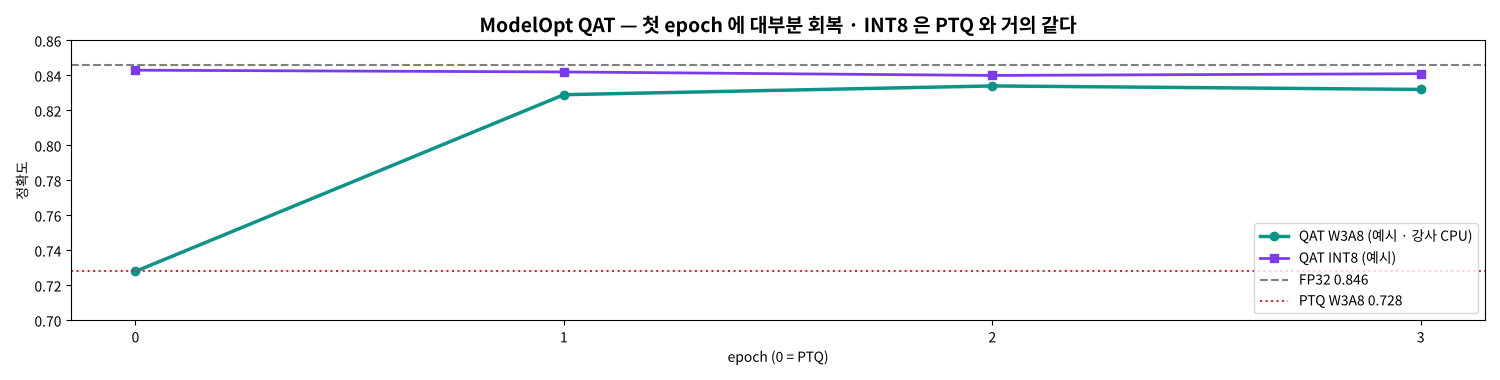

In [ ]:
#@title 🖼 그림 — ModelOpt QAT — PTQ 모델을 그대로 fine-tuning, epoch 마다 정확도 기록
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day4/img/f6_curve.png", embed=True, width=860))

**✍️ 직접 구현 6-1** 5-2 의 W3A8 ModelOpt PTQ 모델 `mo3` 를 `train_qat` 로 QAT 하면서 epoch 마다 정확도를 기록해 `hist_df` (열 `epoch`, `acc` — epoch 0 은 QAT 전 PTQ 값, 1 ~ EPOCHS 는 각 epoch 뒤) 를 만드세요. 걸린 시간은 `t_mo_qat3`, 최종 정확도는 `acc_mo_qat3`.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 6-1 — 실행할 때마다 하나씩
show_hint("6-1", "YGhpc3QgPSBbeyJlcG9jaCI6IDAsICJhY2MiOiBhY2NfbW9fcHRxM31dYCDroZwg7Iuc7J6RLh5gdHJhaW5fcWF0KG1vMywgb25fZXBvY2g9bGFtYmRhIGVwLCBtOiBoaXN0LmFwcGVuZCh7ImVwb2NoIjogZXAgKyAxLCAiYWNjIjogYWNjX3RvcmNoKG0pfSkpYCDigJQg7Iuk7Iq1IDQtMiDsnZgg7ZWo7IiYIOq3uOuMgOuhnC4eYGhpc3RfZGYgPSBwZC5EYXRhRnJhbWUoaGlzdClgLCDrp4jsp4Drp4kg7ZaJ7J20IOy1nOyihSDsoJXtmZXrj4Qu")

In [ ]:
# ✍️ 직접 구현 6-1 — ModelOpt QAT (W3A8) 와 정확도 곡선
hist_df = None        # TODO: 열 epoch, acc (0 ~ EPOCHS)
t_mo_qat3 = None      # TODO
acc_mo_qat3 = None    # TODO
display(hist_df.round(4).T)

In [ ]:
assert list(hist_df.epoch) == list(range(EPOCHS + 1)) and acc_mo_qat3 > acc_mo_ptq3 + 0.05 and acc_mo_qat3 == acc_torch(mo3)
print(f"✅ ModelOpt QAT W3A8 {acc_mo_ptq3:.3f} → {acc_mo_qat3:.3f} ({t_mo_qat3:.0f}초)")

In [ ]:
#@title 🔒 정답 보기 6-1 — 강사가 알려 준 실습 6-1 잠금 코드를 입력하세요
show_answer("6-1", (
    "l9wpK3hL3uK7zk3ijB+ykPmhjQ8z/jvv+rNphwgHbBrxPbCJxdnuCCGo1f6140f13zn7V6Sot07B3NnrYH7QQcay"
    "H1uN31V0zIHHIKm3KfiBBIXI/jyX+DNYfRqHRsTf00g5CV8L2OfqJk/PCVjia22JbIKUvBaW6jp9gj1kfQahDBai"
    "lkrdUradahsXBQUjSGslTHhNYxnDgAGN+uAe6gqbe87OP1dE8JMcxfX+Allnfdv0TH0jbZxN5ZZj7HaTeWKB1A7B"
    "r1oPBCYDMDwLjdUiYwR8Ao3HiToE6eld37WkLwKL1IkMXNroM18u30PZ1yzB6uMlEv3+iQaqIPz1loqNgyvYPHqf"
    "cEjbkzFb74kRXHegGJzjzfePhJize9alSb+I0c9c0ot2puxDbGGXgrEYaOPbcd9alEPM+6Wr0V91RMzEWf2is4Ot"
    "lbX8UylZd4l+GeaRUI/CpQ5dCV7Bx9RdvjfNtpOvrMZnLYHbcKoHWOv8APVwsvtbrsCYWO2rbrIG/9fzNm2ypPS2"
    "iuq0YoXHfLq2KlKHiZZnU8ygR57Y1hyfvBjrgXIZdKOwDfYsfWkh0ldaV4HtoKF+3F+jBhE0pKsG56GvPQ6x3hZ2"
    "kjck0XT/WuVQDUvaAFygSdsVd4v1eYztdBbesQLt5TWXupZOecLGq7VlySjK9AemP1uMv4iUvRzL+Udcgw8QeyGR"
    "sBrpLolX1hIu50/69Ocvte8Euk9+9ShGIgJX4ljhEGh0hmkJqdtjZkwocLh68mlVlBSUB2X5ZYxLptgYJpRzRKey"
    "EYQmNGe7SH7AcTawrxKrIx/vQE+ZOGYS3JQVZUC33VqZdWDzqRUH1HBprDRXxakGNZzZ3oI2u1rZYjPhH/73mSYv"
    "/hDaxWuUsqAUJHQkfC7Brobf9afeKNfVZMj9Ke1k2DvMdxX0zCT0V/fmflwvm8GgDxZ3hL6xwcaitZRt5eAnnDqK"
    "+KHgGXT1wkvxcXOLD0MNv8xSej/75/JeMZizA/pS6xav6Msbo2LxXumivHVQ7uMSaWfCdPwntThFI1isTTth9BxX"
    "bNVmFUiQ1ZNlIfJe97E="
))


**✍️ 직접 구현 6-2** 5-1 의 **INT8** ModelOpt 모델 `mo8` 도 QAT 하고 (`acc_mo_qat8`, `t_mo_qat8`), `mto.save(mo8, "rn20_mo_qat8.pth")` 로 저장하세요. 그리고 새 `load_rn20()` 모델에 `mto.restore(새모델, "rn20_mo_qat8.pth")` 로 복원해 정확도 `acc_restored` 가 같은지 확인합니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 6-2 — 실행할 때마다 하나씩
show_hint("6-2", "YHRfbW9fcWF0OCA9IHRyYWluX3FhdChtbzgpYCDihpIgYGFjY190b3JjaChtbzgpYC4e7KCA7J6lOiBgbXRvLnNhdmUobW84LCAicm4yMF9tb19xYXQ4LnB0aCIpYC4e67O17JuQOiBgbXRvLnJlc3RvcmUobG9hZF9ybjIwKCkudG8oREVWKSwgInJuMjBfbW9fcWF0OC5wdGgiKWAg4oCUIOu5iCBGUDMyIOuqqOuNuOyXkCDslpHsnpDtmZQg6rWs7KGw6rmM7KeAIOuLpOyLnCDslIzsm4Hri4jri6Qu")

In [ ]:
# ✍️ 직접 구현 6-2 — INT8 QAT · 체크포인트 저장 · 복원
t_mo_qat8, acc_mo_qat8 = None, None    # TODO
# TODO: 저장 · 복원
acc_restored = None                    # TODO
print(f"QAT {acc_mo_qat8:.4f} | 복원 {acc_restored:.4f}")

In [ ]:
assert os.path.exists("rn20_mo_qat8.pth") and abs(acc_restored - acc_mo_qat8) < 1e-9 and abs(acc_mo_qat8 - acc_mo_ptq8) < 0.015
print(f"✅ 체크포인트 복원 그대로 · INT8 에서 QAT 이득 {(acc_mo_qat8 - acc_mo_ptq8) * 100:+.1f}%p — 8비트는 PTQ 로 충분")

In [ ]:
#@title 🔒 정답 보기 6-2 — 강사가 알려 준 실습 6-2 잠금 코드를 입력하세요
show_answer("6-2", (
    "56b5uYlPj1hMs/O9IAvz8rqS0McKzmwi98qISZhRo+l2ryn1W2lHMP48DDDR/tJHXwkNkJGvbFz5DTDl1A/VDuf5"
    "6+x5p/nSZXu71UKeFRowLWuKf8eTWKVlHZ9KRNinIOV8dvPxbqMCCP+0jJHSwC9p4gPO8D168iNUaoJs2KLiSNaf"
    "AkTYXDlc1IybWAdlUlv0aGQxut+gs9R7IGGqbpevG5r768Vo3cmN7yhbgBjZCW0A2MG9mDTlLnniMDv6jr2JuLZQ"
    "qFr/dUKg4K9YzPpBh8ovsV+yaTNElVPEML/oiUwUzgQQlbALptUWKMrhi//otj1w8eHkOedYfJUZo4g6SCZdPdXe"
    "YYcP8udUUhrJS/Qpyp/H0Ed5WY11b8mD6wWGLc5sPQMpMuuQxs+N2n5vu9WSNNpkDG/bpIWzRkJEPQZTgYLRc9P8"
    "stVEr2WW6l8VuKQlKdOiyunb89SELpHlGKYNV8PuxRLMHjeAFkaTog2ZFK6VEslDRW6j6YcJQXxb81AN5VaGYu3O"
    "A4mephHKCSKeB4wR9Q74YLqLdFrAnxUBxiOD0AdphdE6QhpOW2YhZIziIdoopr2R3Z6LgxsPhi0lwK+Or6x0mxik"
    "FDfIQBR7znXiLM6oWHwfeWFlKnXHXhVARy/JjUI2cl/655TjbvYcCwxSChv7eGafrDQeknRTa6kMjfF68Ei4+NJb"
    "cNGPj/n4xjSpmqtctri+vCuJVfo2Yj5fQ+oPWV0IPgJzPGTy/WK/fFEedpSSHeHTF1T3E6GTj+843vAjJ+ihx7RZ"
    "Yx9eJHupQbho4iMiTzToNKn6V/i9G/RlbyJ3P3Oupv/jqyjVCqFmyPjzFLJbcqOMxsFiI1fpKU3roF9pDN8aDXk1"
    "voaSZkFmlIvCffZDlrLxX0BsloONruKHxXYKLjdkIpbUFCW/u8QSOUDxo8n13R1ixSe4t0dLYRUVFiwLIzf8of1J"
    "xrm+MYdnufXacA6NanpmUrMJxYoWgjp72O0Ov9jr6xRhCw=="
))


#### 📌 6교시 정리

- ModelOpt QAT = **PTQ 모델을 평소처럼 학습** (양자화기 안에 STE).
- 체크포인트는 `mto.save` / `mto.restore` — 양자화 구조까지 저장.
- W3A8 은 QAT 로 크게 회복, INT8 은 PTQ 와 거의 같다 — QAT 가 필요한 곳을 숫자로 판단한다.

## 7교시 — QAT 모델 배포: QDQ ONNX · TensorRT INT8

ModelOpt 로 양자화한 모델을 `torch.onnx.export` 하면 양자화기가 **QuantizeLinear · DequantizeLinear** 로 바뀐 **QDQ ONNX** 가 나옵니다 (Day 3 의 explicit 경로). scale 이 이미 들어 있으므로 TensorRT 빌드에 **보정이 필요 없습니다** — `trtexec --onnx=rn20_qat.onnx --int8 --fp16` 과 같습니다.

**Netron 에서 확인할 것** — Conv 마다 입력 쪽에 Q→DQ, weight 쪽에 Q→DQ (채널별 scale) 가 붙어 있습니다. BN 은 Conv 뒤에 남아 있고 TensorRT 가 빌드할 때 접습니다.

> QDQ ONNX 의 weight 는 아직 **FP32** 로 저장돼 있어 파일이 FP32 와 비슷한 크기입니다. 진짜로 작아지는 것은 **엔진**입니다.

> 🎬 **애니메이션** [D4-7 QAT 모델 배포](https://imguru-mooc.github.io/AI_CAMPUS/QP-day4/animation.html#d4-7)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

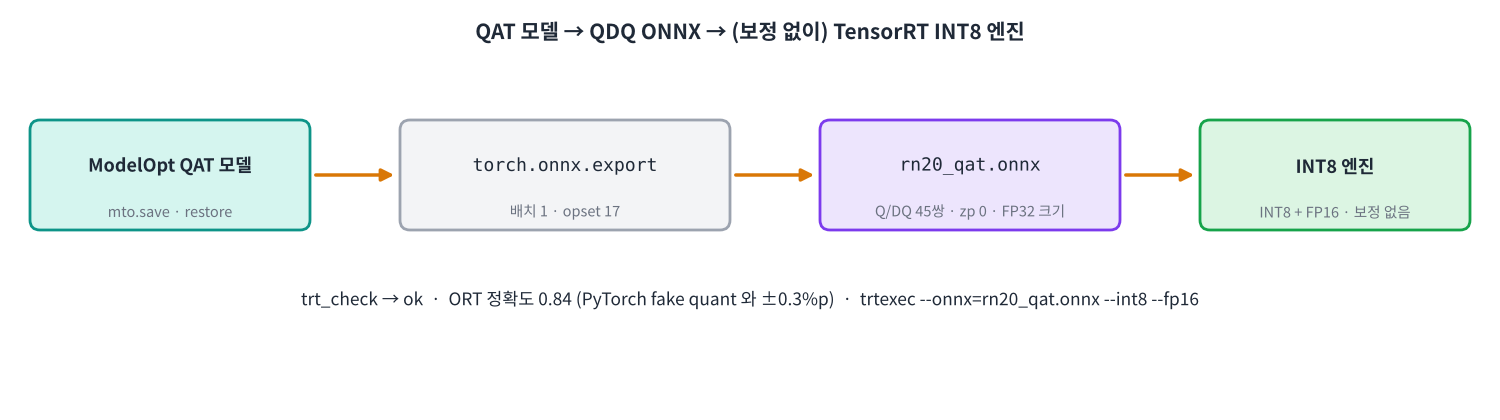

In [ ]:
#@title 🖼 그림 — QAT 모델 → QDQ ONNX → (보정 없이) TensorRT INT8 엔진
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day4/img/f7_deploy.png", embed=True, width=860))

**✍️ 직접 구현 7-1** 6-2 의 QAT 모델 `mo8` 을 배치 1 고정으로 `rn20_qat.onnx` 에 내보내세요 (`export_b1`). Q · DQ 노드 수 `n_q`, `n_dq`, TensorRT 조건 `trt_check`, ONNX Runtime 정확도 `acc_qat_onnx` 를 확인합니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 7-1 — 실행할 때마다 하나씩
show_hint("7-1", "YGV4cG9ydF9iMShjb3B5LmRlZXBjb3B5KG1vOCksICJybjIwX3FhdC5vbm54IilgIOKAlCBleHBvcnRfYjEg7J20IENQVSDroZwg7Jiu6rKoIOuwsOy5mCAxIOuhnCDrgrTrs7Trg4Xri4jri6QuHmBDb3VudGVyKG4ub3BfdHlwZSBmb3IgbiBpbiBvbm54LmxvYWQo6rK966GcKS5ncmFwaC5ub2RlKWAg66GcIFEgwrcgRFEg6rCc7IiYLh5gdHJ0X2NoZWNrKOqyveuhnClgLCBgb25ueF9hY2Mo6rK966GcKWAu")

In [ ]:
# ✍️ 직접 구현 7-1 — QDQ ONNX 로 내보내기
# TODO: export
n_q, n_dq = None, None     # TODO
acc_qat_onnx = None        # TODO
print(f"Q {n_q} · DQ {n_dq} | {trt_check('rn20_qat.onnx')} | ORT {acc_qat_onnx:.4f}")

In [ ]:
assert n_q == n_dq == 44 + 1 or (n_q == n_dq and 40 <= n_q <= 50)
assert trt_check("rn20_qat.onnx")["ok"] and abs(acc_qat_onnx - acc_mo_qat8) < 0.01
print(f"✅ QDQ ONNX — Q/DQ {n_q}쌍 · zero_point 모두 0 · ORT 정확도 {acc_qat_onnx:.4f} (PyTorch {acc_mo_qat8:.4f})")

In [ ]:
#@title 🔒 정답 보기 7-1 — 강사가 알려 준 실습 7-1 잠금 코드를 입력하세요
show_answer("7-1", (
    "4/Io//gE0BAnL8T78XJurPOxTGQs3QPMXvUyXDXudxq5i36DptJCQo+VAvOiSL6Q5zJ4UFMRYMb3nVPCrviKVD7B"
    "uvfYOZ42osRbtVZ1jwfoc6YoU9lTigZ7PV0Ic9x3nNlQMxMIpcStLkRuMZP/R4D+Upm3PmEjs/+ntGUvS8ocLGLB"
    "uMsxdtVgj8G6K1XbcAjfGY1I8DCKwDsBTjVApRZq5xhp/NssgynEqH/gR72RyOCIS9doYRylkmqbwYBtnMC8eNTM"
    "5YOD/jNje4/Ek/izONAa3mUvJ/6AdhkTUtpHoU0OmGbZxiIlhgxmy304mYjIAh+qOKKB5VpgpPaOKNJBL2CSMODl"
    "5LpwnLCyoNS5foW2Ikwe0B7oj0+pre9VZe2cyUAwSrwhNMbG/qLQU/BCoeILxtWlYIrWdwcndkOvfNT0PA/a/d9Y"
    "EDAVDulitSQreLcTnIgZ3Ximn7Jktwet5VAF97Afezf/zrbnTLu7c46x+oLYohJaFQJ3P4Svltq9Tiaq2Vvuf9jQ"
    "HCjyb35QuJRhpZ1JG9GksXl6MjKTqzMSV41mQl6J9G3hWmctD7PTBGfbGcxUXhz1f93vruaPQ/mJLm9CKeqLecSu"
    "vVGK5qhx+E5I/nqnzbkWiAjNeJcWzFLbERO3XOznRrtPPRadwutp8+T2baK1NNH+hrkVTwvrAaxTa697Y8LBMhKo"
    "kghEW1boAJb2l0w4UddeEipsBoKM1Dmyi3htr/Ecu0pnp4Op2acOMGWx8ggtvAcWMT6nkCE0A3gf/4YxHbt/M9Lc"
    "++v2zLO7+yRuOym1CWCNk+/4D6janMbfoT+m8NfFWeSXe/JXkhL7UL1woAfvqcWZaFiOdLsl63fJkUrlClK8u90f"
    "97o8t1EyV4kEi2q758pY7tDvJEu4oL7ZFA1ceY9cda3jlZhkjVxHzKkQVHvugc1FHlcIT+ghw7eRXvEF2IB5fMSN"
    "7y4qCcntnNvkiouO4QqkyX/6BE145OV5SRHMiXO5nJIS00idhMPBCecMikvg3lz3NBCZP8pPSbCL/Fr4VuIvC5og"
    "c/k/eF6Ozz7oqfc0U54lrm5ySl28FA=="
))


**✍️ 직접 구현 7-2** `rn20_qat.onnx` 로 INT8 엔진 `rn20_qat.engine` 을 만들어 (`build_once`, `fp16=True, int8=True` — 보정 없음) 정확도 · 지연 시간 · 크기를 `deploy_row` 사전 (`model`, `backend`, `acc`, `mean_ms`, `size_kb`) 로 재세요. GPU 가 없으면 ONNX Runtime CPU 로 같은 값을 잽니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 7-2 — 실행할 때마다 하나씩
show_hint("7-2", "R1BVOiBgVFJUSW5mZXIoYnVpbGRfb25jZSgicm4yMF9xYXQub25ueCIsICJybjIwX3FhdC5lbmdpbmUiLCBmcDE2PVRydWUsIGludDg9VHJ1ZSkpYC4eQ1BVOiBgcyA9IG1ha2Vfc2Vzc2lvbigicm4yMF9xYXQub25ueCIpOyBpbmZlciA9IGxhbWJkYSB4LCBzPXM6IHMucnVuKE5vbmUsIHsiaW5wdXQiOiB4fSlbMF1gLh7soJXtmZXrj4TripQgMiwwMDDsnqXsnYQg7ZWcIOyepeyUqSwg7KeA7Jew7J2AIGBiZW5jaF9mbihsYW1iZGE6IGluZmVyKFhfZXZbOjFdKSwgbj0zMDAsIHdhcm09MzApWyJtZWFuIl1gLCDtgazquLDripQg7JeU7KeEIChHUFUpIOuYkOuKlCBPTk5YIChDUFUpLg==")

In [ ]:
# ✍️ 직접 구현 7-2 — 보정 없이 INT8 엔진
deploy_row = None   # TODO: {"model", "backend", "acc", "mean_ms", "size_kb"}
print(deploy_row)

In [ ]:
assert set(deploy_row) == {"model", "backend", "acc", "mean_ms", "size_kb"} and abs(deploy_row["acc"] - acc_qat_onnx) < 0.01 and deploy_row["mean_ms"] > 0
print(f"✅ {BACKEND}: QAT INT8 정확도 {deploy_row['acc']:.4f} · {deploy_row['mean_ms']:.3f} ms · {deploy_row['size_kb']:.0f} KB")

In [ ]:
#@title 🔒 정답 보기 7-2 — 강사가 알려 준 실습 7-2 잠금 코드를 입력하세요
show_answer("7-2", (
    "VjsUaVz1v63xKu8ogYfcSMg0Mt1vKn40XsmQuWw8k+xRqdolsDsK9DHm+gTOXB3qU9ALTIr6AGkFCI/R7Pv8//J+"
    "iOLZrqrWgAmiYiIcOKK58pr6EpFOBID0bb2g/aAAmXu1Qwfz25nKLRqMXD6GQ95GETOQ2tj9YNPBgHi03yVbaXMn"
    "vWKnuaYnlKKcxlApqWPqPSadDxxrXf+7V4bFLS6bbWsazhWiJVAvaDdTZR+RcPWKKfzhf7vqDkGyFuR+eFAbX5Ic"
    "dNZlDpCinc9WWsgK1bVo+X5mhQQ50IEBexh1O6m+tuXG9W4lZG8hPF+x/rYqZyuvozGCFMoBslZFs+UtSSEpJSul"
    "aGnvXniby2ZrZb8CfKjqVCCCWlwcAKkZe89u4Y8OIsDxH2qP+G5SjiuqjqHP88BolqqolqJFvEDT85G8aJ/ZPE9F"
    "uZyqSrP98psF0b5+qtIE20LNCSLU5Y/PKftjpQbVjYqLIxNKECQPus86AdOzqujoU8t9c1Jc9y85mOZ2XS6qsIt+"
    "9eSQ5APX3m+rDK5sXyZdYkTW+r2auPYTY0ydmNMHNQd7YuGWrUPVQAGfYzjhCZYv1of8hzybQ1xlYJrG9jF6+yhl"
    "Ek8mb5bu2BHnjHgpVmlZGPTy9rhRqZJ23flzmWfnqye8R8w3ryo949XXORDZyyi6W3owKRox+BHvy6q1EeUFWOtH"
    "NbfYZUueoOpGEaXzKfAH2xzqd03JXHIyIEUfSSEXtLFdh5GTYu1S9uY84fTu14QuRCJBF6g5mrVN+ZknHA9+IVzM"
    "mP1Ehz1w05oKbmKLNPJOuEUA66KknN9oBvrmDVEewkWZTdRQJ1yjecHwWG/87CwQpQZ4JEH7y49kAghq6EiSUtGA"
    "iJgL9YD2ZijL2wWuU2zoLKDhEGnvY7flA7Q2vS4OENUUzPspTosKurBFZSh/jdGnCOsLH+aXE1TmUnUvSaz6N16M"
    "xZAj963VBQSda/VGcCzKPDdSAQ5M1B6yxQ+yYY2sKAaNmZ0spFRlQpH5jAgi/EeFADP8rlkELVyze3fzKu+x8tIK"
    "vPO10jV5DDw+t0O9z0K4RLhaZVSFPRaBhT6fQztT5fhYSTKRjed+IsU6CyUMTSSid+us00clWlvUabHBzFnHNVg0"
    "KLgoJc1cWIE/fziNuEKiAsknS/HenCKWlTdeNyFCjHoX/siHoMcHoQBICQjJE90twLnzhzPcBqztYVsxlqqb+mi1"
    "aEahk0BL"
))


#### 📌 7교시 정리

- ModelOpt 모델 → `torch.onnx.export` → **QDQ ONNX** (scale 포함 · zero_point 0).
- TensorRT 빌드는 **보정 없이** `INT8 + FP16` — Day 3 와 같은 함수.
- QDQ ONNX 는 FP32 크기, **엔진**이 작다. Netron 으로 Q/DQ 위치를 확인한다.

## 8교시 — 미니 프로젝트: PTQ vs QAT 대결

같은 ResNet-20 을 **5가지 방법**으로 양자화해 한 표에 놓고, "QAT 가 필요한 경우" 를 숫자로 결론 냅니다.

| 방법 | INT8 (W8A8) | W3A8 | 학습 |
|---|---|---|---|
| FP32 | (기준 0.846) | (기준) | — |
| ORT PTQ | `rn20_ptq8.onnx` (예제 1-A) | — (3비트 불가) | 없음 |
| ModelOpt PTQ | `acc_mo_ptq8` (5-1) | `acc_mo_ptq3` (5-2) | 없음 |
| 수작업 QAT | **과제 1** 에서 학습 | `acc_qat3` (실습 4-2) | 3 epoch |
| ModelOpt QAT | `acc_mo_qat8` (6-2) | `acc_mo_qat3` (6-1) | 3 epoch |

| 과제 | 내용 | 배점 |
|---|---|---|
| 1 | 수작업 QAT INT8 학습 + ModelOpt PTQ INT8 를 ONNX 로 | 20 |
| 2 | 대결 표 `duel_df` (정확도 2종 · 학습 분 · 지연) | 20 |
| 3 | QAT 이득 계산 · "QAT 필요?" 판정 | 20 |
| 4 | `ptq_vs_qat.csv` · `qp_baseline.csv` 저장 | 20 |
| 5 | 정확도 곡선 그림 저장 | 10 |
| 6 | 결론 쓰기 (마크다운) | 10 |

> 미니 프로젝트에는 **정답 보기 셀이 없습니다.** 채점 셀을 실행하면 자동 채점 점수와 **정답 열람 기록**이 나옵니다 (과제 6 은 강사 채점).

> 🎬 **애니메이션** [D4-8 PTQ vs QAT 대결](https://imguru-mooc.github.io/AI_CAMPUS/QP-day4/animation.html#d4-8)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

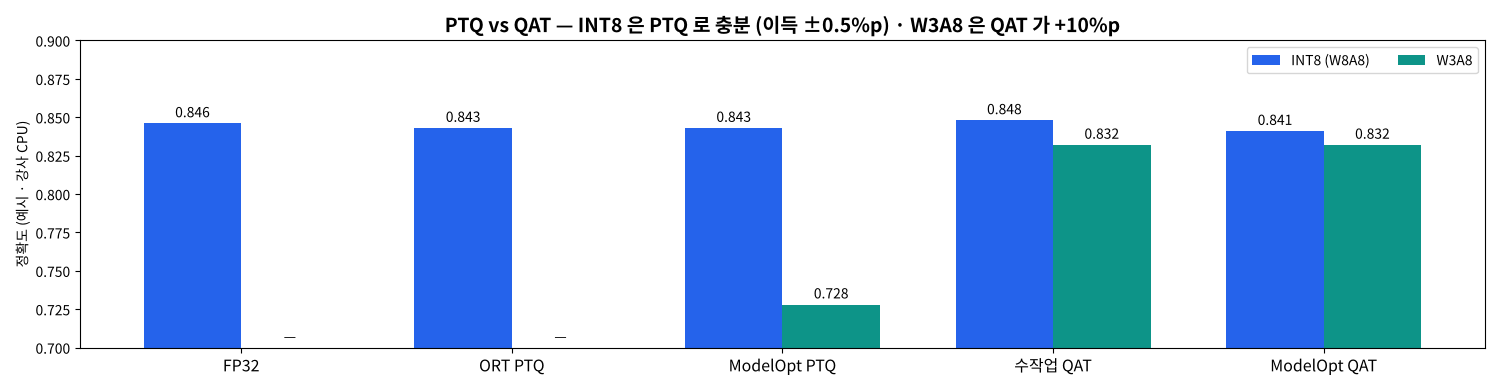

In [ ]:
#@title 🖼 그림 — PTQ vs QAT 대결 — 정확도 · 학습 비용 · 지연을 한 표에
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day4/img/f8_duel.png", embed=True, width=860))

**과제 1 (20점)** (1) `quantize_model(rn20, 8, 8)` → `calibrate` 한 수작업 INT8 모델을 `train_qat` 로 QAT 해서 `acc_qat8`, `t_qat8` 을 구하세요. (2) 5-1 의 ModelOpt **PTQ** INT8 모델을 다시 만들어 (`mtq.quantize`) `rn20_mo_ptq8.onnx` 로 내보내고 ORT 정확도 `acc_mo_ptq8_onnx` 를 구하세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 8-1 — 실행할 때마다 하나씩
show_hint("8-1", "KDEpIGBxOCA9IGNhbGlicmF0ZShxdWFudGl6ZV9tb2RlbChybjIwLCA4LCA4KSlgIOKGkiBgdF9xYXQ4ID0gdHJhaW5fcWF0KHE4KWAuHigyKSBgbXRxLnF1YW50aXplKGNvcHkuZGVlcGNvcHkocm4yMCkudG8oREVWKSwgbXRxLklOVDhfREVGQVVMVF9DRkcsIGZvcndhcmRfbG9vcD1mb3J3YXJkX2xvb3ApYCDihpIgYGV4cG9ydF9iMSguLi4sICJybjIwX21vX3B0cTgub25ueCIpYCDihpIgYG9ubnhfYWNjYC4=")

In [ ]:
# ✍️ 과제 1 — 수작업 QAT INT8 · ModelOpt PTQ INT8 ONNX
acc_qat8, t_qat8 = None, None    # TODO
acc_mo_ptq8_onnx = None          # TODO
print(f"수작업 QAT INT8 {acc_qat8:.4f} ({t_qat8:.0f}초) | ModelOpt PTQ INT8 ONNX {acc_mo_ptq8_onnx:.4f}")

**과제 2 (20점)** 위 표대로 `duel_df` 를 만드세요. 행 순서 `FP32, ORT PTQ, ModelOpt PTQ, 수작업 QAT, ModelOpt QAT`, 열 `method, acc_int8, acc_w3a8, train_min, latency_ms`.
- `acc_int8`: FP32 는 `base_df` 의 FP32, 나머지는 각 INT8 정확도 (ORT PTQ 는 `base_df`). `acc_w3a8`: 없으면 `NaN` (FP32 · ORT PTQ).
- `train_min`: QAT 두 방법은 (INT8 + W3A8 학습 시간) / 60, 나머지 0.
- `latency_ms`: `deploy_lat(onnx)` (아래 시작 코드 — GPU 면 TensorRT 엔진, 아니면 ORT) 로 FP32 `rn20_b1_pre.onnx` · ORT PTQ `rn20_ptq8.onnx` · ModelOpt PTQ `rn20_mo_ptq8.onnx` · ModelOpt QAT `rn20_qat.onnx`. 수작업 QAT 는 `NaN`.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 8-2 — 실행할 때마다 하나씩
show_hint("8-2", "YGRlcGxveV9sYXRgIOydgCDslYTrnpgg7Iuc7J6RIOy9lOuTnOyXkCDsnojsirXri4jri6Qg4oCUIE9OTlgg6rK966Gc66eMIOuEo+ycvOuptCDrkKnri4jri6QuHk9SVCBQVFEgwrcgRlAzMiDsnZgg7KCV7ZmV64+E64qUIGBiYXNlX2RmLnNldF9pbmRleCgibW9kZWwiKS5hY2NgLh7tlZnsirUg67aEOiBgKHRfcWF0OCArIHRfcWF0MykgLyA2MGAsIGAodF9tb19xYXQ4ICsgdF9tb19xYXQzKSAvIDYwYC4=")

In [ ]:
# ✍️ 과제 2 — 대결 표
def deploy_lat(onnx_path):
    """GPU 면 TensorRT (FP32 는 플래그 없음, QDQ 는 INT8+FP16), 아니면 ORT CPU — 배치 1 평균 ms"""
    if TRT_OK:
        q = trt_check(onnx_path)["qdq"] > 0
        f = TRTInfer(build_once(onnx_path, onnx_path.replace(".onnx", ".engine"), fp16=q, int8=q))
    else:
        s = make_session(onnx_path); f = lambda x, s=s: s.run(None, {"input": x})[0]
    return bench_fn(lambda: f(X_ev[:1]), n=300, warm=30)["mean"]

duel_df = None   # TODO: 5행 · 열 method, acc_int8, acc_w3a8, train_min, latency_ms
display(duel_df.round(4))

**과제 3 (20점)** QAT 이득을 계산하세요: `gain = {"INT8": 두 QAT 중 높은 정확도 − 두 PTQ (ORT · ModelOpt) 중 높은 정확도, "W3A8": 두 QAT 중 높은 것 − ModelOpt PTQ}`. 그리고 이득이 **0.01 (1%p) 을 넘으면 QAT 필요** 로 판정한 `need_qat = {"INT8": bool, "W3A8": bool}` 을 만드세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 8-3 — 실행할 때마다 하나씩
show_hint("8-3", "YGRfID0gZHVlbF9kZi5zZXRfaW5kZXgoIm1ldGhvZCIpYCDroZwg7J2066aE7Jy866GcIOq6vOuDheuLiOuLpC4eSU5UODogbWF4KFFBVCDrkZgpIOKIkiBtYXgoUFRRIOuRmCksIFczQTg6IG1heChRQVQg65GYKSDiiJIgTW9kZWxPcHQgUFRRLh5gbmVlZF9xYXQgPSB7azogYm9vbCh2ID4gMC4wMSkgZm9yIGssIHYgaW4gZ2Fpbi5pdGVtcygpfWAu")

In [ ]:
# ✍️ 과제 3 — QAT 이득과 판정
gain = None       # TODO: {"INT8": .., "W3A8": ..}
need_qat = None   # TODO
print(gain, need_qat)

**과제 4 (20점)** `duel_df` 를 `ptq_vs_qat.csv` 로 저장하고, `qp_baseline.csv` 에 **5행** (`day="Day4"`, `model="rn20_<method>"`, `quant="INT8 (<method>)"`, `acc=acc_int8`, `mean_ms=latency_ms`, 나머지 `size_kb · p95_ms · fps_b32` 는 NaN) 을 추가하세요. 파일이 없으면 새로 만들고, 같은 (day, model) 은 마지막 것만 남깁니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 8-4 — 실행할 때마다 하나씩
show_hint("8-4", "YGR1ZWxfZGYudG9fY3N2KCJwdHFfdnNfcWF0LmNzdiIsIGluZGV4PUZhbHNlKWAuHmBkdWVsX2RmLml0ZXJ0dXBsZXMoKWAg66GcIDXqsJzsnZgg7ZaJIOyCrOyghCDihpIg6riw7KG0IGNzdiDsmYAgYHBkLmNvbmNhdGAg4oaSIGBkcm9wX2R1cGxpY2F0ZXMoc3Vic2V0PVsiZGF5IiwgIm1vZGVsIl0sIGtlZXA9Imxhc3QiKWAu")

In [ ]:
# ✍️ 과제 4 — 저장
# TODO: ptq_vs_qat.csv · qp_baseline.csv

**과제 5 (10점)** 6-1 의 `hist_df` (ModelOpt QAT W3A8) 정확도 곡선에 **PTQ W3A8 (점선)** · **FP32 (회색 점선)** 기준선을 함께 그려 `qat_curve.png` 로 저장하세요 (제목 · 축 이름 포함).

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 8-5 — 실행할 때마다 하나씩
show_hint("8-5", "YHBsdC5wbG90KGhpc3RfZGYuZXBvY2gsIGhpc3RfZGYuYWNjLCAiby0iKWAgKyBgcGx0LmF4aGxpbmUoYWNjX21vX3B0cTMsIGxzPSItLSIpYCArIGBwbHQuYXhobGluZSgwLjg0NiwgbHM9Ii0tIiwgYz0iZ3JheSIpYC4e7KCc66qpIMK3IOy2lSDsnbTrpoQgwrcg67KU66GAIOKGkiBgcGx0LnNhdmVmaWcoInFhdF9jdXJ2ZS5wbmciLCBkcGk9MTIwKWAu")

In [ ]:
# ✍️ 과제 5 — 정확도 곡선 그림
# TODO

### 과제 6 — 결론: QAT 가 필요한 경우 (10점)

아래 셀에 답을 쓰세요 (각 2~3줄).

1. 오늘 대결 결과로 본 **"QAT 가 필요한 경우"** 와 **"PTQ 로 충분한 경우"** 를 숫자 (이득 %p · 학습 분) 와 함께.
2. 수작업 QAT 와 ModelOpt QAT 의 정확도가 비슷했는데, 실제 배포에는 어느 쪽을 쓰겠습니까? 이유는?
3. Day 3 BadQuantNet 같은 outlier 모델에 QAT 를 쓰면 어떻게 될까요? (강사 실험: ModelOpt QAT 0.25 → 0.50) 어떤 처방이 더 나을까요?
4. W3A8 모델을 실제 장치에서 빠르게 돌리려면 무엇이 더 필요할까요?

✍️ *여기에 답을 쓰세요.*

### 채점 셀

In [ ]:
score = 0
try:
    assert acc_qat8 > 0.83 and t_qat8 > 0 and trt_check("rn20_mo_ptq8.onnx")["ok"] and acc_mo_ptq8_onnx > 0.83
    score += 20; print("✅ 과제 1  +20")
except Exception as e: print("❌ 과제 1", repr(e))
try:
    assert list(duel_df.method) == ["FP32", "ORT PTQ", "ModelOpt PTQ", "수작업 QAT", "ModelOpt QAT"]
    assert list(duel_df.columns) == ["method", "acc_int8", "acc_w3a8", "train_min", "latency_ms"]
    assert duel_df.acc_w3a8.isna().tolist() == [True, True, False, False, False] and duel_df.latency_ms.isna().tolist() == [False, False, False, True, False]
    assert (duel_df.train_min[[0, 1, 2]] == 0).all() and (duel_df.train_min[[3, 4]] > 0).all() and abs(duel_df.acc_int8[3] - acc_qat8) < 1e-9
    score += 20; print("✅ 과제 2  +20")
except Exception as e: print("❌ 과제 2", repr(e))
try:
    d_ = duel_df.set_index("method")
    g8 = max(d_.acc_int8["수작업 QAT"], d_.acc_int8["ModelOpt QAT"]) - max(d_.acc_int8["ORT PTQ"], d_.acc_int8["ModelOpt PTQ"])
    g3 = max(d_.acc_w3a8["수작업 QAT"], d_.acc_w3a8["ModelOpt QAT"]) - d_.acc_w3a8["ModelOpt PTQ"]
    assert abs(gain["INT8"] - g8) < 1e-9 and abs(gain["W3A8"] - g3) < 1e-9 and need_qat == {"INT8": g8 > 0.01, "W3A8": g3 > 0.01}
    score += 20; print("✅ 과제 3  +20")
except Exception as e: print("❌ 과제 3", repr(e))
try:
    c_ = pd.read_csv("ptq_vs_qat.csv"); b_ = pd.read_csv("qp_baseline.csv")
    assert len(c_) == 5 and (b_.day == "Day4").sum() == 5 and set(b_[b_.day == "Day4"].model) == {f"rn20_{m}" for m in duel_df.method}
    score += 20; print("✅ 과제 4  +20")
except Exception as e: print("❌ 과제 4", repr(e))
try:
    assert os.path.getsize("qat_curve.png") > 5000
    score += 10; print("✅ 과제 5  +10")
except Exception as e: print("❌ 과제 5", repr(e))
print(f"\n자동 채점 {score} / 90  (+ 과제 6 강사 채점 10점) | 장치: {DEV} · 측정: {BACKEND}")
seen = [l.split("\t")[0] for l in open(".qp_answer_log")] if os.path.exists(".qp_answer_log") else []
seen = list(dict.fromkeys(seen))
print(f"정답 열람 {len(seen)}개" + (f" — {', '.join(seen)}" if seen else " — 없음 👍"))

#### 📌 8교시 정리

- 같은 모델 · 같은 자로 **5가지 방법**을 비교 — INT8 은 PTQ 로 충분, W3A8 은 QAT 필요.
- QAT 의 비용 (학습 시간 · GPU) 과 이득 (%p) 을 함께 적어야 결론이 선다.
- 배포는 ModelOpt → QDQ ONNX → TensorRT. 저비트는 실행 커널이 있는지까지 확인한다.

## 오늘의 정리

### 셀프 체크

- [ ] 비트 수에 따른 PTQ 정확도를 재고, QAT 가 필요한 상황을 설명할 수 있다
- [ ] fake quant (quantize → dequantize) 함수 · 모듈을 만들고, weight · 활성값의 차이를 안다
- [ ] round 의 기울기가 0 인 문제와 STE (`torch.autograd.Function`) · 범위 밖 기울기 0 을 설명할 수 있다
- [ ] BN 을 먼저 접고 QConv2d 로 바꿔 직접 QAT 를 했다
- [ ] `mtq.quantize` 로 PTQ · QAT 를 하고 `mto.save` / `restore` 로 저장 · 복원했다
- [ ] QAT 모델을 QDQ ONNX 로 내보내 보정 없이 TensorRT INT8 엔진을 만들었다
- [ ] PTQ vs QAT 5종 대결로 'QAT 가 필요한 경우' 를 숫자로 결론 냈다

### 내일 (Day 5) 예고

양자화는 '숫자를 작게', 내일의 **Pruning (가지치기)** 은 '숫자를 적게' 입니다. unstructured (weight 0 만들기) 와 structured (채널 통째로 빼기) 를 측정으로 비교하고, 가지치기 뒤 fine-tuning 으로 정확도를 되찾습니다 — 오늘의 `train_qat` 가 그대로 fine-tuning 루프가 됩니다.

## 📝 Day 4 복습 퀴즈 — 수업이 끝난 뒤

오늘 배운 1~8교시 내용을 **24문항**으로 점검합니다. 9가지 유형이 섞여 있습니다.

👉 **[Day 4 복습 퀴즈 열기](https://imguru-mooc.github.io/AI_CAMPUS/QP-day4/review_quiz.html)**

1. 이름을 입력하고 24문항을 모두 풉니다.
2. **채점하기** → 정오와 해설이 나타납니다. 채점 후에는 답이 잠깁니다.
3. **제출 (오답 정리)** → 점수 · 결과 코드 · 오답 정리를 **텍스트 복사** 또는 캡처로 강사가 안내한 곳에 제출합니다.